<a href="https://colab.research.google.com/github/carpotru08-cmd/Introducci-n_Ciencia_Datos_UdeM/blob/main/Trabajo_Final/ML_Rentabilidad_Final_Ciencia_Datos_Entrega_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo final integrado de rentabilidad — Ventas 2022–2025
## Workbook integral: EDA → Preprocesamiento → Regresión → Validación avanzada → Interpretación → Negocio

### Pregunta de negocio

> **¿Qué características de las ventas, productos, clientes, canales y periodos están asociadas con una mayor rentabilidad y cuáles tienen mayor capacidad para explicar o predecir el margen de ganancia?**

La rentabilidad se representa mediante:

`Profit_Margin`

---

## Decisión principal: regresión

`Profit_Margin` es una variable **numérica continua**.

Por eso el problema principal sigue siendo:

### Aprendizaje supervisado → Regresión

No convertimos el problema principal en clasificación porque hacerlo perdería información sobre la magnitud real del margen.

Al final podemos traducir la predicción continua a una alerta de negocio, por ejemplo:

`Profit_Margin predicho < 15 % → alerta`

sin cambiar el objetivo principal del modelo.


# 0. Estrategia metodológica

Este workbook conserva las cuatro etapas de preprocesamiento vistas en clase:

1. **Imputación y Missing Indicator**
2. **Codificación de variables categóricas**
3. **Escalado y normalización**
4. **Texto y vectorización**

Después incorpora un flujo completo de Machine Learning:

- baseline con `DummyRegressor`;
- comparación de varias familias de regresión;
- cross-validation solamente dentro de train;
- tuning con Optuna;
- selección por desempeño + parsimonia;
- test reservado hasta el final;
- análisis de calidad del target;
- chequeo de leakage por grupos (`Order_ID` y `Customer_ID`);
- prueba de una variable a la vez como stress-test de leakage;
- data drift con PSI;
- validación adversarial train vs. test;
- validación temporal 2022–2024 → 2025;
- importancia por permutación;
- interpretación global y local con SHAP;
- análisis de variables y dimensiones de negocio;
- alerta operativa;
- simulación de descuentos.

> **Importante:** el objetivo es construir evidencia predictiva. Asociación e importancia del modelo no equivalen automáticamente a causalidad.



- intervalos de confianza bootstrap para márgenes descriptivos clave;
- asociaciones crudas vs. asociaciones ajustadas por la estructura económica de la venta;
- capacidad predictiva por bloques de negocio: dimensión sola y pérdida al retirarla;
- matriz de volumen vs. eficiencia ajustada para priorizar oportunidades comerciales;


## Alineación con el cierre de la Clase 8

El flujo final queda:

**Problema → datos → calidad → EDA → features → split → preprocessing → baseline → CV → modelos → leakage avanzado → tuning → selección → test → drift → validación temporal → interpretación → decisión de negocio**

### ¿Qué NO aplica?

`SMOTE`, `class_weight` y otras técnicas de balanceo no forman parte del modelo principal porque el target `Profit_Margin` es continuo y estamos resolviendo una **regresión**.

La regla posterior de margen `< 15 %` es una aplicación operativa del resultado y no transforma el entrenamiento principal en clasificación.


# 1. Librerías

In [ ]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GroupKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict
)

from sklearn.impute import (
    SimpleImputer,
    KNNImputer,
    MissingIndicator
)

from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    Normalizer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.dummy import DummyRegressor

from sklearn.linear_model import (
    LinearRegression,
    Ridge
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

RANDOM_STATE = 42

# 2. Carga de datos

La carga se mantiene intencionalmente simple.

Necesitamos:

- el dataset limpio producido por el EDA;
- el dataset original para recuperar los valores faltantes que existían antes de la limpieza.

In [ ]:
df = pd.read_csv(
    "/content/Sales_transactions_2022_2025_limpio.csv"
)

df_original = pd.read_csv(
    "/content/Sales_transactions_2022_2025.csv"
)

print("Dataset limpio   :", df.shape)
print("Dataset original :", df_original.shape)

display(df.head())

Dataset limpio   : (18000, 47)
Dataset original : (18045, 36)


,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,Store_ID,Store_Name,Country,Region,City,Product_ID,Product_Name,Product_Category,Product_Subcategory,Quantity,Unit_Price,Discount_Percentage,Sales_Amount,Cost_Amount,Profit,Payment_Method,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year,Profit_Margin,Gross_Sales,Discount_Amount,Has_Promotion,Order_Month,Order_Quarter,Year_Quarter,Day_of_Week,Age_Group,Is_Returned,Period_Group
0,T02016694,O0116694,C01482,Sophia Smith,28,Male,Consumer,2022-10-06,11:30:55,Online,LA-01,Los Angeles Downtown,United States,West,Los Angeles,P026,Webcam HD,Electronics,Cameras,2,85.29,5.0,162.05,115.61,46.44,Credit Card,Completed,Standard,4,No,Not Applicable,James Anderson,SAVE10,4.0,81,2022,28.657822,170.58,8.53,1,10,4,2022-Q4,Thursday,26-35,0,Q4
1,T02016374,O0108187,C01591,Hannah King,46,Female,Consumer,2024-06-03,17:06:29,Online,SYD-01,Sydney CBD,Australia,New South Wales,Sydney,P005,Office Keyboard,Electronics,Accessories,6,58.85,15.0,300.13,237.00,63.13,Debit Card,Completed,Standard,6,No,Not Applicable,Ella Lewis,No Promotion,5.0,123,2024,21.034219,353.10,52.97,0,6,2,2024-Q2,Monday,46-55,0,Q1-Q3
2,T02004099,O0104099,C04140,Emma Wilson,42,Male,Consumer,2024-12-19,08:22:11,Online,PAR-01,Paris Central,France,Île-de-France,Paris,P017,Copy Paper Box,Office Supplies,Paper,2,43.92,15.0,74.66,73.17,1.49,Credit Card,Shipped,Standard,4,No,Not Applicable,Liam Davis,No Promotion,4.0,93,2024,1.995714,87.84,13.18,0,12,4,2024-Q4,Thursday,36-45,0,Q4
3,T02010280,O0110280,C03663,Daniel Clark,18,Male,Corporate,2025-10-05,14:32:43,B2B Portal,NYC-01,New York Central,United States,Northeast,New York,P008,SmartDock USB-C,Electronics,Accessories,11,115.34,15.0,1078.46,897.91,180.55,PayPal,Completed,Next Day,2,No,Not Applicable,Grace Harris,HOLIDAY20,NaN,59,2025,16.741465,1268.74,190.28,1,10,4,2025-Q4,Sunday,18-25,0,Q4
4,T02012685,O0112685,C02749,Sophia Smith,37,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,CHI-01,Chicago Loop,United States,Midwest,Chicago,P013,Desk Lamp,Furniture,Lighting,4,69.71,15.0,237.03,164.95,72.08,Apple Pay,Completed,Express,2,No,Not Applicable,Sophia Brown,No Promotion,2.0,56,2022,30.409653,278.84,41.81,0,9,3,2022-Q3,Tuesday,36-45,0,Q1-Q3


# 3. Puente entre el EDA y Machine Learning

Antes de construir el modelo verificamos dos ideas centrales del EDA:

1. la rentabilidad debe medirse con un **margen agregado correcto**;
2. Q4 mostró más volumen y descuentos, pero menor eficiencia.

El margen agregado se calcula como:

`100 × suma(Profit) / suma(Sales_Amount)`

No utilizamos simplemente la media de los márgenes individuales porque transacciones de tamaños muy distintos no deberían pesar igual.

In [ ]:
def margen_agregado(datos):
    ventas = datos["Sales_Amount"].sum()

    if ventas == 0:
        return np.nan

    return (
        100
        * datos["Profit"].sum()
        / ventas
    )


print(
    "Margen agregado global:",
    round(margen_agregado(df), 2),
    "%"
)

Margen agregado global: 19.98 %


In [ ]:
if "Order_Quarter" in df.columns:

    puente_q = (
        df
        .assign(
            Grupo_Periodo=np.where(
                df["Order_Quarter"].astype(str) == "4",
                "Q4",
                "Q1-Q3"
            )
        )
        .groupby("Grupo_Periodo")
        .agg(
            Transacciones=("Sales_Amount", "size"),
            Ventas=("Sales_Amount", "sum"),
            Utilidad=("Profit", "sum"),
            Descuento_Promedio=("Discount_Percentage", "mean")
        )
    )

    margen_q = (
        df
        .assign(
            Grupo_Periodo=np.where(
                df["Order_Quarter"].astype(str) == "4",
                "Q4",
                "Q1-Q3"
            )
        )
        .groupby("Grupo_Periodo")
        .apply(margen_agregado)
        .rename("Margen_Agregado")
    )

    puente_q = puente_q.join(margen_q)

    display(
        puente_q.round(2)
    )

,Transacciones,Ventas,Utilidad,Descuento_Promedio,Margen_Agregado
Grupo_Periodo,,,,,
Q1-Q3,12134,5536553.83,1211467.31,4.00,21.88
Q4,5866,2697536.77,433972.09,10.91,16.09


Este bloque no pretende repetir todo el EDA.

Su función es conectar el análisis exploratorio con la siguiente pregunta:

> Si Q4 presenta menor margen, ¿el trimestre realmente aporta información propia o la diferencia puede explicarse mejor por variables como producto y descuento?

Eso se estudiará con el modelo multivariado.


# 3A. Incertidumbre del EDA — intervalos de confianza con bootstrap

Hasta ahora calculamos márgenes agregados por diferentes grupos.

Pero una diferencia observada entre categorías o periodos puede ser:

- un patrón relativamente estable;
- o una diferencia afectada por variabilidad muestral.

Para añadir contexto usamos **bootstrap**.

## ¿Qué hace bootstrap?

1. toma muchas muestras con reemplazo dentro de un grupo;
2. recalcula el margen agregado en cada muestra;
3. usa la distribución obtenida para construir un intervalo de confianza aproximado del 95 %.

No convierte el análisis en causal.

Simplemente añade una idea de **incertidumbre** alrededor del margen observado.

En este notebook lo aplicamos a dimensiones clave para la pregunta de negocio:

- categoría de producto;
- banda de descuento;
- canal de venta;
- trimestre.


In [ ]:

N_BOOT = 300


def bootstrap_margen(
    datos,
    n_boot=N_BOOT,
    seed=RANDOM_STATE
):

    rng = np.random.default_rng(
        seed
    )

    n = len(
        datos
    )

    margen_real = margen_agregado(
        datos
    )

    if n < 2:

        return pd.Series({
            "Margen": margen_real,
            "IC95_inf": np.nan,
            "IC95_sup": np.nan
        })

    valores = []

    for _ in range(
        n_boot
    ):

        posiciones = rng.integers(
            0,
            n,
            n
        )

        muestra = datos.iloc[
            posiciones
        ]

        valores.append(
            margen_agregado(
                muestra
            )
        )

    return pd.Series({
        "Margen": margen_real,
        "IC95_inf":
            np.nanpercentile(
                valores,
                2.5
            ),
        "IC95_sup":
            np.nanpercentile(
                valores,
                97.5
            )
    })


# Bandas de descuento para lectura descriptiva
bins_descuento = [
    -0.01,
    0,
    5,
    10,
    15,
    20,
    np.inf
]

labels_descuento = [
    "0%",
    "1-5%",
    "6-10%",
    "11-15%",
    "16-20%",
    ">20%"
]

df[
    "Banda_Descuento"
] = pd.cut(
    df[
        "Discount_Percentage"
    ],
    bins=bins_descuento,
    labels=labels_descuento
)


In [ ]:

dimensiones_bootstrap = [
    "Product_Category",
    "Banda_Descuento",
    "Sales_Channel",
    "Order_Quarter"
]

resultados_bootstrap = {}

for variable in dimensiones_bootstrap:

    if variable not in df.columns:
        continue

    tabla = (
        df
        .groupby(
            variable,
            dropna=False,
            observed=True
        )
        .apply(
            bootstrap_margen
        )
        .reset_index()
    )

    resultados_bootstrap[
        variable
    ] = tabla

    print(
        "\nMARGEN + IC95%:",
        variable
    )

    display(
        tabla.round(2)
    )



MARGEN + IC95%: Product_Category


,Product_Category,Margen,IC95_inf,IC95_sup
0,Appliances,22.01,21.56,22.42
1,Electronics,19.34,19.01,19.60
2,Furniture,21.15,20.71,21.61
3,Office Supplies,19.51,19.08,19.92



MARGEN + IC95%: Banda_Descuento


,Banda_Descuento,Margen,IC95_inf,IC95_sup
0,0%,25.07,24.90,25.22
1,1-5%,20.82,20.60,21.09
2,6-10%,16.74,16.50,17.00
3,11-15%,11.89,11.49,12.25
4,16-20%,6.43,5.72,7.10
5,>20%,0.39,-0.57,1.57



MARGEN + IC95%: Sales_Channel


,Sales_Channel,Margen,IC95_inf,IC95_sup
0,B2B Portal,19.79,19.15,20.45
1,Online,20.24,19.99,20.51
2,Phone Order,19.67,19.02,20.38
3,Retail Store,19.90,19.61,20.19



MARGEN + IC95%: Order_Quarter


,Order_Quarter,Margen,IC95_inf,IC95_sup
0,1,21.37,21.04,21.72
1,2,21.15,20.74,21.53
2,3,23.11,22.78,23.39
3,4,16.09,15.65,16.47



### Cómo interpretar los intervalos

Ejemplo conceptual:

`Furniture → margen 21.2 % | IC95% 20.5–21.9 %`

Esto significa que, bajo el procedimiento bootstrap aplicado a nuestra muestra, el margen estimado se concentra aproximadamente dentro de ese rango.

**No debemos interpretar automáticamente el solapamiento o no solapamiento de intervalos como una prueba formal de causalidad o significancia entre grupos.**

Su objetivo aquí es dar contexto a las diferencias descriptivas.


# 4. Selección de variables

Una buena predicción no sirve si utiliza información que no estaría disponible al momento de analizar la venta.

Por eso dividimos las variables en tres grupos.

## 4.1 Variables prohibidas por leakage

No usamos:

- `Profit`
- `Sales_Amount`
- `Cost_Amount`
- `Gross_Sales`
- `Discount_Amount`

**¿Por qué?**

`Profit_Margin` está estructuralmente ligado a esas variables. Incluirlas permitiría al modelo reconstruir la respuesta casi directamente.

## 4.2 Variables posteriores a la venta

No usamos:

- `Return_Flag`
- `Return_Reason`
- `Is_Returned`
- `Delivery_Days`
- `Customer_Rating`
- `Order_Status`

**¿Por qué?**

Si queremos utilizar el modelo antes o al momento de aprobar una venta, esta información todavía no existe.

## 4.3 Identificadores

Tampoco usamos IDs ni nombres de clientes.

No representan una característica de negocio generalizable y pueden favorecer memorización.

## 4.4 Variables seleccionadas

Para evitar redundancias mantenemos una representación compacta:

### Numéricas

- `Discount_Percentage`
- `Quantity`
- `Unit_Price`
- `Inventory_Level`

### Ordinal

- `Age_Group`

### Nominales

- producto y categoría;
- canal;
- segmento y género;
- país;
- envío y pago;
- promoción;
- trimestre, año y día.

### Decisiones de simplificación

- usamos `Age_Group` en lugar de `Customer_Age`;
- usamos `Country` y no simultáneamente `Region` y `City`;
- usamos `Order_Quarter` y no `Order_Month`;
- incluimos `Product_Name` porque el producto puede tener una estructura de costos y margen propia;
- `Product_Name` se tratará como **categoría**, no como texto libre.

In [ ]:
target = "Profit_Margin"

numeric_features = [
    "Discount_Percentage",
    "Quantity",
    "Unit_Price",
    "Inventory_Level"
]

ordinal_features = [
    "Age_Group"
]

nominal_features = [
    "Product_Category",
    "Product_Name",
    "Sales_Channel",
    "Customer_Segment",
    "Customer_Gender",
    "Country",
    "Shipping_Method",
    "Payment_Method",
    "Promotion_Code",
    "Order_Quarter",
    "Order_Year",
    "Day_of_Week"
]

features = (
    numeric_features
    + ordinal_features
    + nominal_features
)

leakage_columns = [
    "Profit",
    "Profit_Margin",
    "Sales_Amount",
    "Cost_Amount",
    "Gross_Sales",
    "Discount_Amount"
]

post_sale_columns = [
    "Return_Flag",
    "Return_Reason",
    "Is_Returned",
    "Delivery_Days",
    "Customer_Rating",
    "Order_Status"
]

print("Target:", target)
print("Número de predictores:", len(features))
print("Numéricas:", numeric_features)
print("Ordinal:", ordinal_features)
print("Nominales:", nominal_features)

Target: Profit_Margin
Número de predictores: 17
Numéricas: ['Discount_Percentage', 'Quantity', 'Unit_Price', 'Inventory_Level']
Ordinal: ['Age_Group']
Nominales: ['Product_Category', 'Product_Name', 'Sales_Channel', 'Customer_Segment', 'Customer_Gender', 'Country', 'Shipping_Method', 'Payment_Method', 'Promotion_Code', 'Order_Quarter', 'Order_Year', 'Day_of_Week']


## 4.5 Verificación automática de leakage

In [ ]:
leakage_en_X = sorted(
    set(features).intersection(
        leakage_columns
    )
)

print(
    "Variables de leakage dentro de X:",
    leakage_en_X
)

assert len(leakage_en_X) == 0

print("Verificación superada.")

Variables de leakage dentro de X: []
Verificación superada.


# 5. Recuperar los valores faltantes originales

Durante el EDA algunos valores faltantes fueron tratados para poder analizar el dataset completo.

Para Machine Learning queremos que cualquier imputación se aprenda **solo con entrenamiento**.

Por eso:

1. usamos `Transaction_ID` para alinear el dataset limpio con el original;
2. restauramos los `NaN`;
3. después hacemos el `train_test_split`.

### Caso especial: `Promotion_Code`

Durante el EDA la ausencia de código se interpretó como **sin promoción**.

Por eso no restauramos esos valores como `NaN`: en este caso la ausencia tiene significado de negocio.

In [ ]:
df_original_ml = (
    df_original
    .drop_duplicates()
    .copy()
)

if df["Transaction_ID"].duplicated().any():
    raise ValueError(
        "Transaction_ID está duplicado en el dataset limpio."
    )

if df_original_ml["Transaction_ID"].duplicated().any():
    raise ValueError(
        "Transaction_ID sigue duplicado en el dataset original."
    )

original_indexado = (
    df_original_ml
    .set_index("Transaction_ID")
)

for columna in features:

    if columna == "Promotion_Code":
        continue

    if columna in original_indexado.columns:

        ids_nan = original_indexado.index[
            original_indexado[columna].isna()
        ]

        mask = df["Transaction_ID"].isin(
            ids_nan
        )

        df.loc[
            mask,
            columna
        ] = np.nan


# Age_Group depende de Customer_Age
edad_original = original_indexado[
    "Customer_Age"
]

ids_edad_problematicos = edad_original.index[
    edad_original.isna()
    | (edad_original < 18)
    | (edad_original > 100)
]

mask_age = df["Transaction_ID"].isin(
    ids_edad_problematicos
)

df.loc[
    mask_age,
    "Age_Group"
] = np.nan

In [ ]:
# Trimestre y año se tratarán como categorías,
# no como magnitudes numéricas.

for col in ["Order_Quarter", "Order_Year"]:

    if col in df.columns:

        df[col] = (
            df[col]
            .astype("Int64")
            .astype("string")
        )


X = df[features].copy()
y = df[target].copy()

print("X:", X.shape)
print("y:", y.shape)

faltantes = pd.DataFrame({
    "NaN": X.isna().sum(),
    "% NaN": X.isna().mean() * 100
})

display(
    faltantes[
        faltantes["NaN"] > 0
    ]
    .sort_values(
        "% NaN",
        ascending=False
    )
    .round(2)
)

X: (18000, 17)
y: (18000,)


,NaN,% NaN
Age_Group,219,1.22
Inventory_Level,198,1.10
Customer_Gender,162,0.90
Product_Name,144,0.80
Payment_Method,144,0.80


# 6. Calidad financiera del target

Antes de entrenar revisamos una inconsistencia detectada durante el EDA:

`Profit` debería ser aproximadamente igual a:

`Sales_Amount - Cost_Amount`

No eliminaremos registros silenciosamente ni reemplazaremos el `Profit` reportado.

En cambio:

1. cuantificamos cuántos registros presentan discrepancias;
2. conservamos el target original;
3. después del modelado realizamos un **análisis de sensibilidad** para medir cuánto afectan estas anomalías al desempeño.

Usamos una tolerancia de **$0.02** para evitar marcar diferencias puramente de redondeo.

In [ ]:
TOLERANCIA_PROFIT = 0.02

df[
    "Profit_Esperado"
] = (
    df["Sales_Amount"]
    - df["Cost_Amount"]
)

df[
    "Diferencia_Profit"
] = (
    df["Profit"]
    - df["Profit_Esperado"]
)

df[
    "Profit_Consistente"
] = (
    df["Diferencia_Profit"].abs()
    <= TOLERANCIA_PROFIT
)

n_inconsistentes = (
    (~df["Profit_Consistente"])
    .sum()
)

pct_inconsistentes = (
    n_inconsistentes
    / len(df)
    * 100
)

print(
    "Registros con inconsistencia:",
    n_inconsistentes
)

print(
    f"Porcentaje: {pct_inconsistentes:.2f}%"
)

display(
    df.loc[
        ~df["Profit_Consistente"],
        [
            "Transaction_ID",
            "Sales_Amount",
            "Cost_Amount",
            "Profit",
            "Profit_Esperado",
            "Diferencia_Profit",
            "Profit_Margin"
        ]
    ]
    .sort_values(
        "Diferencia_Profit",
        key=lambda s: s.abs(),
        ascending=False
    )
    .head(15)
    .round(2)
)

Registros con inconsistencia: 110
Porcentaje: 0.61%


,Transaction_ID,Sales_Amount,Cost_Amount,Profit,Profit_Esperado,Diferencia_Profit,Profit_Margin
14654,T02001097,2538.06,1853.19,363.30,684.87,-321.57,14.31
13050,T02016187,6932.33,5680.08,1553.94,1252.25,301.69,22.42
16315,T02012502,28.36,18.35,-280.34,10.01,-290.35,-988.50
10710,T02007752,291.26,236.11,-230.44,55.15,-285.59,-79.12
1857,T02000839,225.45,188.78,296.92,36.67,260.25,131.70
12880,T02002263,1034.86,968.33,291.57,66.53,225.04,28.17
13511,T02008620,1156.89,983.31,380.81,173.58,207.23,32.92
1985,T02002589,364.43,263.34,288.34,101.09,187.25,79.12
5819,T02010522,329.54,233.36,268.95,96.18,172.77,81.61
6541,T02000696,1068.64,994.75,245.89,73.89,172.00,23.01


### Decisión

Los registros inconsistentes **se conservan** porque el proyecto decidió trabajar con el `Profit` reportado.

Sin embargo, las métricas finales deben interpretarse junto con un análisis de sensibilidad sobre los registros financieramente consistentes. Así distinguimos entre limitaciones del modelo y posibles problemas de calidad del target.

# 7. División entrenamiento / prueba

Usaremos:

- 80 % entrenamiento;
- 20 % test final.

Todas las decisiones de:

- imputación;
- codificación;
- escalado;
- selección del modelo

se tomarán **solamente dentro de train**, utilizando validación cruzada.

`X_test` no participa en esas decisiones.

Esto evita que el desempeño final quede artificialmente optimista.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (14400, 17)
Test : (3600, 17)



## 7.1 ¿Dónde está la validación?

La Clase 8 diferencia conceptualmente tres funciones:

- **Train:** datos disponibles para aprender.
- **Validación:** datos usados para comparar decisiones y ajustar hiperparámetros.
- **Test:** examen final independiente.

En este notebook no separamos un bloque fijo adicional llamado `validation`.

En cambio, la **validación ocurre mediante cross-validation dentro de `X_train`**. Cada fold funciona temporalmente como validación y el resto como entrenamiento.

Por eso la lógica es:

`80 % train → cross-validation para decidir`

`20 % test → evaluación final`

### ¿Por qué usamos split aleatorio y no temporal?

La pregunta principal busca identificar qué variables explican o predicen el margen dentro del histórico de transacciones, no hacer un pronóstico explícito del futuro.

Por eso mantenemos el split aleatorio.

Si el objetivo operacional cambiara a:

> “entrenar con años anteriores y predecir específicamente ventas futuras”,

sería más apropiado utilizar un corte temporal o `TimeSeriesSplit`.


---
# ETAPA 1 — Imputación y Missing Indicator

Comparamos las tres estrategias principales vistas en clase:

1. `SimpleImputer`
2. `KNNImputer`
3. `SimpleImputer + MissingIndicator`

## ¿Por qué no elegir una automáticamente?

Porque una técnica más compleja solo tiene sentido si aporta una mejora útil.

Además, los faltantes pueden comportarse de formas distintas:

- puede bastar con una mediana;
- puede ser útil buscar observaciones similares;
- o el hecho de que un dato esté ausente puede contener señal.

In [ ]:
missing_train = pd.DataFrame({
    "Cantidad_NaN": X_train.isna().sum(),
    "Porcentaje_NaN": X_train.isna().mean() * 100
})

missing_train = (
    missing_train[
        missing_train["Cantidad_NaN"] > 0
    ]
    .sort_values(
        "Porcentaje_NaN",
        ascending=False
    )
)

display(
    missing_train.round(2)
)

,Cantidad_NaN,Porcentaje_NaN
Age_Group,185,1.28
Inventory_Level,158,1.10
Customer_Gender,129,0.90
Payment_Method,118,0.82
Product_Name,109,0.76


## 7.1 Configuración auxiliar

Para comparar imputaciones necesitamos un modelo.

Usamos temporalmente:

- `StandardScaler`;
- `OneHotEncoder`;
- `OrdinalEncoder`;
- `Ridge`.

Estos elementos se mantienen constantes durante la comparación.

El objetivo aquí **no es escoger el modelo final**, sino aislar el efecto de la imputación.

In [ ]:
orden_edad = [
    [
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ]
]


def crear_pipeline_imputacion(tipo):

    if tipo == "knn":

        num_pipe = Pipeline([
            (
                "imputer",
                KNNImputer(
                    n_neighbors=5,
                    weights="distance"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

    else:

        num_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

    ord_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "ordinal",
            OrdinalEncoder(
                categories=orden_edad,
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        )
    ])

    nom_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    transformers = [
        ("num", num_pipe, numeric_features),
        ("ord", ord_pipe, ordinal_features),
        ("nom", nom_pipe, nominal_features)
    ]

    if tipo == "indicator":

        transformers.append(
            (
                "missing",
                MissingIndicator(
                    features="missing-only",
                    error_on_new=False
                ),
                features
            )
        )

    prep = ColumnTransformer(
        transformers=transformers
    )

    return Pipeline([
        ("prep", prep),
        (
            "reg",
            Ridge(alpha=1.0)
        )
    ])

## 7.2 Validación cruzada de imputación

Para que `KNNImputer` no vuelva innecesariamente pesado el ejercicio, la comparación se hace sobre una muestra reproducible de hasta 6.000 filas tomada **solo de train**.

La métrica principal es:

### MAE

Interpretación:

> En promedio, ¿cuántos puntos porcentuales de margen se equivoca el modelo?

In [ ]:
n_imp = min(
    6000,
    len(X_train)
)

X_imp = X_train.sample(
    n=n_imp,
    random_state=RANDOM_STATE
)

y_imp = y_train.loc[
    X_imp.index
]

cv_imp = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

estrategias_imp = {
    "simple": crear_pipeline_imputacion(
        "simple"
    ),
    "knn": crear_pipeline_imputacion(
        "knn"
    ),
    "indicator": crear_pipeline_imputacion(
        "indicator"
    )
}

resultados_imp = []

for clave, modelo in estrategias_imp.items():

    inicio = time.time()

    scores = cross_validate(
        modelo,
        X_imp,
        y_imp,
        cv=cv_imp,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultados_imp.append({
        "Clave": clave,
        "Estrategia": {
            "simple": "SimpleImputer",
            "knn": "KNNImputer",
            "indicator": "Simple + MissingIndicator"
        }[clave],
        "MAE_CV": -scores["test_mae"].mean(),
        "MAE_std": scores["test_mae"].std(),
        "R2_CV": scores["test_r2"].mean(),
        "Tiempo_s": time.time() - inicio
    })


tabla_imputacion = (
    pd.DataFrame(resultados_imp)
    .sort_values(
        "MAE_CV"
    )
    .reset_index(drop=True)
)

display(
    tabla_imputacion.round(4)
)

,Clave,Estrategia,MAE_CV,MAE_std,R2_CV,Tiempo_s
0,indicator,Simple + MissingIndicator,2.3065,0.0440,0.5999,0.4179
1,knn,KNNImputer,2.3066,0.0433,0.5999,0.4008
2,simple,SimpleImputer,2.3066,0.0435,0.5999,0.3776


## 7.3 Decisión: desempeño + parsimonia

No queremos escoger KNN o indicadores por una mejora diminuta.

Regla:

- si una alternativa mejora el MAE de `SimpleImputer` en más de 1 %, la conservamos;
- si no, preferimos la estrategia sencilla.

Esta regla hace explícita la decisión y evita complejidad sin beneficio práctico.

In [ ]:
mae_simple = (
    tabla_imputacion
    .loc[
        tabla_imputacion["Clave"] == "simple",
        "MAE_CV"
    ]
    .iloc[0]
)

mejor_fila_imp = (
    tabla_imputacion
    .iloc[0]
)

mejora_relativa_imp = (
    (mae_simple - mejor_fila_imp["MAE_CV"])
    / mae_simple
)

if (
    mejor_fila_imp["Clave"] != "simple"
    and mejora_relativa_imp > 0.01
):

    mejor_imputacion = (
        mejor_fila_imp["Clave"]
    )

else:

    mejor_imputacion = "simple"


print(
    "Mejor resultado observado:",
    mejor_fila_imp["Estrategia"]
)

print(
    "Mejora frente a SimpleImputer:",
    f"{mejora_relativa_imp * 100:.2f}%"
)

print(
    "Imputación acumulada:",
    mejor_imputacion
)

Mejor resultado observado: Simple + MissingIndicator
Mejora frente a SimpleImputer: 0.00%
Imputación acumulada: simple


---
# ETAPA 2 — Codificación categórica

Ahora conservamos la imputación seleccionada y añadimos la representación de las variables categóricas.

## Variables nominales → One-Hot Encoding

Ejemplos:

- producto;
- canal;
- país;
- método de pago.

No tienen un orden natural.

## Variable ordinal → Ordinal Encoding

`Age_Group` sí tiene un orden:

`18-25 < 26-35 < 36-45 < 46-55 < 56+`

## Trimestre y año

Aunque están escritos como números, los tratamos como categorías para no imponer una relación lineal artificial sobre el margen.

## 8.1 Ejemplo One-Hot

In [ ]:
demo_ohe = (
    X_train[["Sales_Channel"]]
    .dropna()
    .head(8)
)

ohe_demo = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

ohe_array = ohe_demo.fit_transform(
    demo_ohe
)

display(
    pd.concat(
        [
            demo_ohe.reset_index(drop=True),
            pd.DataFrame(
                ohe_array,
                columns=ohe_demo.get_feature_names_out(
                    ["Sales_Channel"]
                )
            )
        ],
        axis=1
    )
)

,Sales_Channel,Sales_Channel_B2B Portal,Sales_Channel_Online,Sales_Channel_Retail Store
0,Online,0.0,1.0,0.0
1,Online,0.0,1.0,0.0
2,Online,0.0,1.0,0.0
3,B2B Portal,1.0,0.0,0.0
4,Online,0.0,1.0,0.0
5,Retail Store,0.0,0.0,1.0
6,Online,0.0,1.0,0.0
7,Retail Store,0.0,0.0,1.0


## 8.2 Ejemplo Ordinal

In [ ]:
demo_age = (
    X_train[["Age_Group"]]
    .dropna()
    .head(8)
)

age_encoder = OrdinalEncoder(
    categories=orden_edad,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

age_cod = age_encoder.fit_transform(
    demo_age
)

display(
    pd.DataFrame({
        "Age_Group": demo_age["Age_Group"].values,
        "Age_Group_cod": age_cod.ravel()
    })
)

,Age_Group,Age_Group_cod
0,36-45,2.0
1,56+,4.0
2,26-35,1.0
3,46-55,3.0
4,18-25,0.0
5,46-55,3.0
6,26-35,1.0
7,26-35,1.0


## 8.3 Frequency Encoding

También mostramos la técnica vista en clase.

No la elegimos como estrategia principal porque tenemos una cardinalidad manejable y One-Hot conserva la identidad del producto, algo importante para estudiar rentabilidad.

In [ ]:
freq_producto = (
    X_train["Product_Name"]
    .value_counts(
        normalize=True
    )
)

demo_freq = (
    X_train[["Product_Name"]]
    .head(10)
    .copy()
)

demo_freq["Frecuencia"] = (
    demo_freq["Product_Name"]
    .map(freq_producto)
)

display(demo_freq)

,Product_Name,Frecuencia
1921,NoiseCancel Headset,0.040445
5732,Webcam HD,0.041914
2455,Ergo Footrest,0.038206
12131,AeroBook 14 Laptop,0.041145
16612,Coffee Machine,0.022602
7136,Copy Paper Box,0.055350
2525,AeroBook 14 Laptop,0.041145
15931,SmartDock USB-C,0.035757
1684,Laser Toner,0.043104
14380,NoiseCancel Headset,0.040445


## 8.4 Preprocesador acumulativo

Esta función incorpora:

- la imputación de Etapa 1;
- la codificación de Etapa 2;
- y permitirá cambiar el escalador en Etapa 3.

In [ ]:
def crear_numeric_pipe(
    imputacion,
    scaler=None
):

    if imputacion == "knn":

        imputer = KNNImputer(
            n_neighbors=5,
            weights="distance"
        )

    else:

        imputer = SimpleImputer(
            strategy="median"
        )

    pasos = [
        ("imputer", imputer)
    ]

    if scaler is not None:

        pasos.append(
            (
                "scaler",
                clone(scaler)
            )
        )

    return Pipeline(pasos)


def crear_preprocesador(
    imputacion,
    scaler=None,
    subset_features=None
):

    if subset_features is None:
        subset_features = features

    num_cols = [
        c for c in numeric_features
        if c in subset_features
    ]

    ord_cols = [
        c for c in ordinal_features
        if c in subset_features
    ]

    nom_cols = [
        c for c in nominal_features
        if c in subset_features
    ]

    transformers = []

    if len(num_cols) > 0:

        transformers.append(
            (
                "num",
                crear_numeric_pipe(
                    imputacion,
                    scaler
                ),
                num_cols
            )
        )

    if len(ord_cols) > 0:

        ord_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "ordinal",
                OrdinalEncoder(
                    categories=orden_edad,
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                )
            )
        ])

        transformers.append(
            (
                "ord",
                ord_pipe,
                ord_cols
            )
        )

    if len(nom_cols) > 0:

        nom_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ])

        transformers.append(
            (
                "nom",
                nom_pipe,
                nom_cols
            )
        )

    if imputacion == "indicator":

        indicadores = [
            c for c in subset_features
            if c in features
        ]

        if len(indicadores) > 0:

            transformers.append(
                (
                    "missing",
                    MissingIndicator(
                        features="missing-only",
                        error_on_new=False
                    ),
                    indicadores
                )
            )

    return ColumnTransformer(
        transformers=transformers
    )

## 8.5 Contraste didáctico: todo como ordinal

Este experimento demuestra por qué una representación numérica arbitraria puede ser engañosa.

Aunque las métricas fueran parecidas, convertir `Online`, `Retail` y `B2B` en 0, 1 y 2 crea una jerarquía que no existe.

La codificación correcta se conserva por coherencia conceptual.

In [ ]:
def crear_preprocesador_todo_ordinal(
    imputacion,
    scaler=None
):

    num_pipe = crear_numeric_pipe(
        imputacion,
        scaler
    )

    cat_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "ordinal",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        )
    ])

    transformers = [
        ("num", num_pipe, numeric_features),
        (
            "cat",
            cat_pipe,
            ordinal_features + nominal_features
        )
    ]

    if imputacion == "indicator":

        transformers.append(
            (
                "missing",
                MissingIndicator(
                    features="missing-only",
                    error_on_new=False
                ),
                features
            )
        )

    return ColumnTransformer(
        transformers=transformers
    )

In [ ]:
cv_pre = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

codificaciones = {
    "Codificación correcta":
        crear_preprocesador(
            mejor_imputacion,
            StandardScaler()
        ),

    "Todo como ordinal":
        crear_preprocesador_todo_ordinal(
            mejor_imputacion,
            StandardScaler()
        )
}

res_cod = []

for nombre, prep in codificaciones.items():

    modelo = Pipeline([
        ("prep", prep),
        ("reg", Ridge(alpha=1.0))
    ])

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv_pre,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    res_cod.append({
        "Estrategia": nombre,
        "MAE_CV": -scores["test_mae"].mean(),
        "R2_CV": scores["test_r2"].mean()
    })


tabla_codificacion = pd.DataFrame(
    res_cod
)

display(
    tabla_codificacion.round(4)
)

,Estrategia,MAE_CV,R2_CV
0,Codificación correcta,1.9646,0.5991
1,Todo como ordinal,5.2876,0.3588


### Decisión de Etapa 2

Se conserva:

- One-Hot para nominales;
- OrdinalEncoder para `Age_Group`.

No elegimos una codificación únicamente porque una métrica cambie unas décimas: la representación debe respetar el significado del dato.

---
# ETAPA 3 — Escalado y normalización

Nuestras numéricas viven en rangos muy distintos.

Ejemplos:

- `Unit_Price` puede estar en cientos o miles;
- `Discount_Percentage` es un porcentaje;
- `Quantity` se mueve en unidades pequeñas.

Los modelos lineales regularizados y los modelos basados en distancia pueden verse afectados por esas diferencias.

Comparamos:

- sin escalado;
- `StandardScaler`;
- `MinMaxScaler`;
- `RobustScaler`;
- `Normalizer`.

In [ ]:
resumen_num = pd.DataFrame({
    "min": X_train[numeric_features].min(),
    "max": X_train[numeric_features].max(),
    "media": X_train[numeric_features].mean(),
    "mediana": X_train[numeric_features].median(),
    "std": X_train[numeric_features].std()
})

display(
    resumen_num.round(2)
)

,min,max,media,mediana,std
Discount_Percentage,0.00,60.00,6.26,5.00,6.85
Quantity,1.00,11.00,2.12,2.00,1.77
Unit_Price,21.39,1425.09,233.30,100.75,293.85
Inventory_Level,0.00,157.00,70.15,70.00,21.95


## 9.1 Interpretación de cada alternativa

### StandardScaler
Expresa cada variable aproximadamente en unidades de desviación estándar.

### MinMaxScaler
Lleva cada variable a un rango común.

### RobustScaler
Utiliza mediana e IQR; es menos sensible a valores extremos.

### Normalizer
Normaliza cada **fila completa**.

Lo estudiamos porque forma parte del material de clase, pero no es un candidato natural para nuestro modelo: queremos preservar el significado de magnitudes como precio y descuento.

In [ ]:
scalers = {
    "Sin escalado": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "Normalizer L2": Normalizer(norm="l2")
}

res_scaler = []

for nombre, scaler in scalers.items():

    inicio = time.time()

    modelo = Pipeline([
        (
            "prep",
            crear_preprocesador(
                mejor_imputacion,
                scaler
            )
        ),
        (
            "reg",
            Ridge(alpha=1.0)
        )
    ])

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv_pre,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    res_scaler.append({
        "Escalado": nombre,
        "MAE_CV": -scores["test_mae"].mean(),
        "MAE_std": scores["test_mae"].std(),
        "R2_CV": scores["test_r2"].mean(),
        "Tiempo_s": time.time() - inicio
    })


tabla_scaler = (
    pd.DataFrame(res_scaler)
    .sort_values("MAE_CV")
    .reset_index(drop=True)
)

display(
    tabla_scaler.round(4)
)

,Escalado,MAE_CV,MAE_std,R2_CV,Tiempo_s
0,MinMaxScaler,1.9629,0.0622,0.5991,0.5900
1,RobustScaler,1.9646,0.0616,0.5991,0.5876
2,StandardScaler,1.9646,0.0616,0.5991,0.6213
3,Sin escalado,1.9647,0.0616,0.5991,0.5719
4,Normalizer L2,3.1671,0.0535,0.5215,0.6098


## 9.2 Decisión de escalado

Usamos el mismo principio de parsimonia:

- `Normalizer` se excluye de la decisión final por su interpretación por fila;
- si otra alternativa mejora a `StandardScaler` por más de 1 %, la conservamos;
- si no, mantenemos `StandardScaler`.

Esto evita convertir el escalado en un dogma: lo evaluamos, pero también justificamos su significado.

In [ ]:
candidatos_scaler = tabla_scaler[
    tabla_scaler["Escalado"] != "Normalizer L2"
].copy()

mejor_fila_scaler = (
    candidatos_scaler
    .sort_values("MAE_CV")
    .iloc[0]
)

mae_standard = (
    candidatos_scaler
    .loc[
        candidatos_scaler["Escalado"] == "StandardScaler",
        "MAE_CV"
    ]
    .iloc[0]
)

mejora_vs_standard = (
    (mae_standard - mejor_fila_scaler["MAE_CV"])
    / mae_standard
)

if (
    mejor_fila_scaler["Escalado"] != "StandardScaler"
    and mejora_vs_standard > 0.01
):

    mejor_scaler_nombre = (
        mejor_fila_scaler["Escalado"]
    )

else:

    mejor_scaler_nombre = "StandardScaler"


mapa_scalers = {
    "Sin escalado": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

mejor_scaler = mapa_scalers[
    mejor_scaler_nombre
]

print(
    "Mejor observado:",
    mejor_fila_scaler["Escalado"]
)

print(
    "Mejora frente a StandardScaler:",
    f"{mejora_vs_standard * 100:.2f}%"
)

print(
    "Escalado acumulado:",
    mejor_scaler_nombre
)

Mejor observado: MinMaxScaler
Mejora frente a StandardScaler: 0.09%
Escalado acumulado: StandardScaler


---
# ETAPA 4 — Texto y vectorización

El material de clase trabaja:

- `CountVectorizer`;
- stopwords;
- n-gramas;
- `TF-IDF`.

Pero antes de aplicar una técnica debemos determinar si existe **texto libre**.

No toda columna de tipo `object` es texto lingüístico.

In [ ]:
posibles_textos = [
    col
    for col in [
        "Customer_Name",
        "Product_Name",
        "Return_Reason"
    ]
    if col in df.columns
]

resumen_texto = []

for col in posibles_textos:

    serie = (
        df[col]
        .dropna()
        .astype(str)
    )

    resumen_texto.append({
        "Variable": col,
        "Valores_unicos": serie.nunique(),
        "Promedio_caracteres": serie.str.len().mean(),
        "Ejemplo": (
            serie.iloc[0]
            if len(serie) > 0
            else ""
        )
    })

display(
    pd.DataFrame(resumen_texto)
)

,Variable,Valores_unicos,Promedio_caracteres,Ejemplo
0,Customer_Name,1180,11.768444,Sophia Smith
1,Product_Name,28,13.920811,Webcam HD
2,Return_Reason,7,13.517111,Not Applicable


## 10.1 Decisión sobre texto

### Customer_Name
No se utiliza: es un identificador.

### Return_Reason
No se utiliza: ocurre después de la venta.

### Product_Name
Sí se utiliza en el modelo, pero como **categoría nominal**.

**¿Por qué no TF-IDF?**

Porque nombres de productos como `"AeroBook 14 Laptop"` funcionan principalmente como etiquetas de catálogo. No tenemos descripciones, comentarios o reseñas donde el significado de las palabras sea el objeto del análisis.

Aun así, realizamos un experimento didáctico con CountVectorizer y TF-IDF para demostrar la técnica.

In [ ]:
product_text_train = (
    X_train["Product_Name"]
    .fillna("")
    .astype(str)
)

count_vec = CountVectorizer(
    ngram_range=(1, 2),
    min_df=2
)

X_count = count_vec.fit_transform(
    product_text_train
)

print(
    "CountVectorizer:",
    X_count.shape
)

print(
    count_vec
    .get_feature_names_out()[:30]
)

CountVectorizer: (14400, 95)
['11' '11 tablet' '14' '14 laptop' '16' '16 laptop' '27' '27 monitor'
 '2tb' 'aerobook' 'aerobook 14' 'air' 'air purifier' 'backup'
 'backup drive' 'box' 'cabinet' 'camera' 'chair' 'chair pro' 'coffee'
 'coffee machine' 'copy' 'copy paper' 'desk' 'desk fan' 'desk lamp'
 'drive' 'drive 2tb' 'edgetab']


In [ ]:
tfidf_vec = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = tfidf_vec.fit_transform(
    product_text_train
)

print(
    "TF-IDF:",
    X_tfidf.shape
)

print(
    tfidf_vec
    .get_feature_names_out()[:30]
)

TF-IDF: (14400, 95)
['11' '11 tablet' '14' '14 laptop' '16' '16 laptop' '27' '27 monitor'
 '2tb' 'aerobook' 'aerobook 14' 'air' 'air purifier' 'backup'
 'backup drive' 'box' 'cabinet' 'camera' 'chair' 'chair pro' 'coffee'
 'coffee machine' 'copy' 'copy paper' 'desk' 'desk fan' 'desk lamp'
 'drive' 'drive 2tb' 'edgetab']


### Decisión de Etapa 4

La vectorización se estudia, pero no entra al pipeline principal.

Esto también es una conclusión válida:

> **Una técnica no debe aplicarse solo para marcarla como completada; debe corresponder al tipo de variable disponible.**

# 11. Pipeline acumulativo después de las cuatro etapas

In [ ]:
preprocesador_final = crear_preprocesador(
    mejor_imputacion,
    mejor_scaler
)

X_train_preparado = (
    preprocesador_final
    .fit_transform(X_train)
)

print(
    "Variables originales:",
    X_train.shape[1]
)

print(
    "Variables después del preprocesamiento:",
    X_train_preparado.shape[1]
)

print(
    "\nEl test sigue reservado."
)

Variables originales: 17
Variables después del preprocesamiento: 92

El test sigue reservado.


---
# 12. Comparación de modelos de regresión

Ahora sí comparamos modelos.

## Baseline

Primero incluimos:

`DummyRegressor`

Este modelo predice siempre una constante.

Sirve para responder:

> ¿Nuestros predictores realmente contienen información o un modelo ingenuo obtiene algo parecido?

## Modelos candidatos

Comparamos:

- regresión lineal;
- Ridge;
- árbol;
- KNN;
- Random Forest;
- Gradient Boosting.

## Métrica principal: MAE

El MAE es especialmente útil porque se interpreta directamente como:

> **error promedio en puntos porcentuales de margen**

También reportamos RMSE, R², variabilidad entre folds y tiempo.

In [ ]:
modelos = {
    "Dummy (media)": DummyRegressor(
        strategy="mean"
    ),

    "Regresión lineal": LinearRegression(),

    "Ridge": Ridge(
        alpha=1.0
    ),

    "Árbol de decisión": DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=25,
        weights="distance"
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=5,
        n_jobs=1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": HistGradientBoostingRegressor(
        learning_rate=0.08,
        max_iter=250,
        random_state=RANDOM_STATE
    )
}

In [ ]:
cv_modelos = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

resultados_modelos = []
pipelines_modelos = {}

for nombre, reg in modelos.items():

    print("Evaluando:", nombre)

    pipe = Pipeline([
        (
            "prep",
            crear_preprocesador(
                mejor_imputacion,
                mejor_scaler
            )
        ),
        (
            "reg",
            reg
        )
    ])

    pipelines_modelos[nombre] = pipe

    inicio = time.time()

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_modelos,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultados_modelos.append({
        "Modelo": nombre,
        "MAE_CV": -scores["test_mae"].mean(),
        "MAE_std": scores["test_mae"].std(),
        "RMSE_CV": -scores["test_rmse"].mean(),
        "R2_CV": scores["test_r2"].mean(),
        "R2_std": scores["test_r2"].std(),
        "Tiempo_s": time.time() - inicio
    })


tabla_modelos = (
    pd.DataFrame(resultados_modelos)
    .sort_values("MAE_CV")
    .reset_index(drop=True)
)

display(
    tabla_modelos.round(4)
)

Evaluando: Dummy (media)
Evaluando: Regresión lineal
Evaluando: Ridge
Evaluando: Árbol de decisión
Evaluando: KNN
Evaluando: Random Forest
Evaluando: Gradient Boosting


,Modelo,MAE_CV,MAE_std,RMSE_CV,R2_CV,R2_std,Tiempo_s
0,Regresión lineal,1.9487,0.1168,7.4102,0.6819,0.2745,2.2196
1,Ridge,1.9495,0.1153,7.4112,0.6819,0.2744,1.9723
2,Random Forest,1.9733,0.1071,7.6730,0.6636,0.2619,146.6979
3,Gradient Boosting,2.0142,0.0867,7.6144,0.6683,0.2644,5.6450
4,Árbol de decisión,2.1728,0.1194,7.9720,0.6367,0.2521,1.2230
5,KNN,4.3209,0.1520,9.5008,0.4726,0.1799,2.7983
6,Dummy (media),7.8273,0.2508,12.5454,-0.0004,0.0003,0.7575


# 13. Selección preliminar antes del tuning

Primero identificamos qué modelos funcionan mejor **sin ajuste formal de hiperparámetros**.

No escogemos automáticamente el primer lugar si la diferencia es mínima.

Procedimiento:

1. excluimos el Dummy de la selección;
2. identificamos el menor MAE;
3. consideramos como prácticamente empatados los modelos cuyo MAE esté a máximo 1 % del mejor;
4. dentro de ese grupo preferimos el modelo más sencillo e interpretable.

Esta selección es **preliminar**.

Todavía no utilizamos `X_test`. Después haremos tuning dentro de train y volveremos a comparar antes de elegir el modelo final.

In [ ]:
tabla_reales = tabla_modelos[
    tabla_modelos["Modelo"] != "Dummy (media)"
].copy()

mejor_mae = (
    tabla_reales["MAE_CV"]
    .min()
)

candidatos_empatados_pre = tabla_reales[
    tabla_reales["MAE_CV"]
    <= mejor_mae * 1.01
].copy()

prioridad_simplicidad = {
    "Regresión lineal": 1,
    "Ridge": 2,
    "Árbol de decisión": 3,
    "KNN": 4,
    "Gradient Boosting": 5,
    "Random Forest": 6
}

candidatos_empatados_pre[
    "Prioridad"
] = candidatos_empatados_pre[
    "Modelo"
].map(
    prioridad_simplicidad
)

candidatos_empatados_pre = (
    candidatos_empatados_pre
    .sort_values(
        [
            "Prioridad",
            "MAE_CV"
        ]
    )
)

mejor_nombre_preliminar = (
    candidatos_empatados_pre
    .iloc[0]["Modelo"]
)

mejor_modelo_preliminar = pipelines_modelos[
    mejor_nombre_preliminar
]

print(
    "Menor MAE absoluto:",
    tabla_reales
    .sort_values("MAE_CV")
    .iloc[0]["Modelo"]
)

print(
    "Modelo preliminar seleccionado con parsimonia:",
    mejor_nombre_preliminar
)

display(
    candidatos_empatados_pre[
        [
            "Modelo",
            "MAE_CV",
            "RMSE_CV",
            "R2_CV",
            "Tiempo_s"
        ]
    ].round(4)
)

Menor MAE absoluto: Regresión lineal
Modelo preliminar seleccionado con parsimonia: Regresión lineal


,Modelo,MAE_CV,RMSE_CV,R2_CV,Tiempo_s
0,Regresión lineal,1.9487,7.4102,0.6819,2.2196
1,Ridge,1.9495,7.4112,0.6819,1.9723


# 13A. Chequeos avanzados de leakage y generalización dentro de train

Hasta ahora evitamos leakage por construcción:

- no usamos variables que reconstruyen el target;
- no usamos información posterior a la venta;
- no ajustamos transformaciones con test.

Ahora agregamos dos verificaciones adicionales.

## 13A.1 Group leakage

Una misma orden o un mismo cliente puede aparecer en varias filas.

Eso plantea una pregunta:

> ¿El buen desempeño depende de que filas relacionadas aparezcan en distintos folds?

Para medirlo usamos `GroupKFold`.

- con `Order_ID`, ninguna orden puede quedar repartida entre entrenamiento y validación del mismo fold;
- con `Customer_ID`, ningún cliente puede quedar repartido.

Si el MAE permanece parecido al CV convencional, tenemos evidencia de que el desempeño no depende de memorizar pedidos o clientes.


In [ ]:
groups_order = (
    df.loc[
        X_train.index,
        "Order_ID"
    ]
    .astype(str)
)

groups_customer = (
    df.loc[
        X_train.index,
        "Customer_ID"
    ]
    .astype(str)
)

modelo_group_check = clone(
    mejor_modelo_preliminar
)

resultados_group = []

# Referencia: CV convencional
scores_regular = cross_validate(
    modelo_group_check,
    X_train,
    y_train,
    cv=KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    n_jobs=1
)

resultados_group.append({
    "Validacion": "KFold convencional",
    "MAE": -scores_regular["test_mae"].mean(),
    "R2": scores_regular["test_r2"].mean()
})

for nombre_grupo, grupos in {
    "GroupKFold por Order_ID": groups_order,
    "GroupKFold por Customer_ID": groups_customer
}.items():

    n_splits = min(
        5,
        grupos.nunique()
    )

    cv_group = GroupKFold(
        n_splits=n_splits
    )

    scores = cross_validate(
        clone(modelo_group_check),
        X_train,
        y_train,
        groups=grupos,
        cv=cv_group,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultados_group.append({
        "Validacion": nombre_grupo,
        "MAE": -scores["test_mae"].mean(),
        "R2": scores["test_r2"].mean()
    })


tabla_group_leakage = pd.DataFrame(
    resultados_group
)

display(
    tabla_group_leakage.round(4)
)


,Validacion,MAE,R2
0,KFold convencional,1.9487,0.6819
1,GroupKFold por Order_ID,1.9535,0.6673
2,GroupKFold por Customer_ID,1.9485,0.7154


### Cómo interpretar el resultado

No buscamos que los números sean exactamente iguales.

La pregunta es si el desempeño **se desploma** cuando prohibimos que el mismo pedido o cliente aparezca en diferentes folds.

- Si permanece parecido → no hay evidencia fuerte de group leakage.
- Si empeora mucho → parte del score anterior podía depender de relaciones repetidas entre grupos.

Este chequeo usa exclusivamente `X_train` y `y_train`.


## 13A.2 Stress-test: una variable a la vez

Otra señal de alarma sería que **una sola variable legítima** obtuviera casi el mismo desempeño que todo el modelo sin una explicación económica razonable.

Probamos cada predictor por separado utilizando el mismo modelo auxiliar `Ridge`.

Esto no sirve para elegir el modelo final.

Sirve para responder:

> ¿Hay alguna variable sospechosamente predictiva por sí sola?


In [ ]:
cv_stress = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

stress_rows = []

for variable in features:

    prep_variable = crear_preprocesador(
        mejor_imputacion,
        mejor_scaler,
        subset_features=[variable]
    )

    pipe_variable = Pipeline([
        ("prep", prep_variable),
        ("reg", Ridge(alpha=1.0))
    ])

    scores = cross_validate(
        pipe_variable,
        X_train[[variable]],
        y_train,
        cv=cv_stress,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    stress_rows.append({
        "Variable": variable,
        "MAE_CV_sola": -scores["test_score"].mean()
    })


tabla_stress_univariado = (
    pd.DataFrame(stress_rows)
    .sort_values("MAE_CV_sola")
    .reset_index(drop=True)
)

display(
    tabla_stress_univariado.head(12).round(4)
)


,Variable,MAE_CV_sola
0,Product_Name,5.2739
1,Discount_Percentage,6.4598
2,Unit_Price,7.1576
3,Order_Quarter,7.5400
4,Product_Category,7.7875
5,Sales_Channel,7.8275
6,Quantity,7.8277
7,Age_Group,7.8280
8,Inventory_Level,7.8285
9,Country,7.8289


### Lectura

Una variable con buen desempeño individual no es automáticamente leakage.

Por ejemplo, `Product_Name` o `Discount_Percentage` pueden ser muy informativas por razones de negocio.

La alarma aparecería si una variable casi reconstruye perfectamente el margen **sin una razón válida y disponible al momento de la predicción**.

Más adelante complementamos este análisis comparando conjuntos reducidos de variables.


# 14. Tuning formal de hiperparámetros — Clase 8

Hasta aquí comparamos modelos con configuraciones razonables, pero todavía no hemos hecho un **tuning formal**.

La Clase 8 propone que los hiperparámetros se ajusten utilizando validación **dentro de train**, manteniendo el test completamente aislado.

Usaremos **Optuna** porque fue una de las herramientas vistas en clase.

## ¿Qué vamos a tunear?

### Ridge
Ajustaremos `alpha`, que controla la intensidad de la regularización.

### Random Forest
Ajustaremos parámetros relacionados con:

- número de árboles;
- profundidad;
- tamaño mínimo de hojas;
- cantidad de variables consideradas en cada división.

### Gradient Boosting
Ajustaremos parámetros como:

- `learning_rate`;
- número de iteraciones;
- número máximo de hojas;
- regularización.

## ¿Por qué no tunear la Regresión Lineal?

`LinearRegression` tiene muy pocos hiperparámetros relevantes para este ejercicio.

Por eso la conservamos como **referencia simple** y verificamos si los modelos tuneados logran una mejora suficientemente grande para justificar mayor complejidad.

> **Regla fundamental:** Optuna nunca verá `X_test` ni `y_test`.

### ¿Y SMOTE?

No se aplica porque nuestro target es continuo y el problema principal es **regresión**, no clasificación desbalanceada. La alerta `< 15 %` se crea después del modelo y no convierte el entrenamiento principal en clasificación.

In [ ]:
# Optuna puede no venir instalado por defecto en todos los entornos.
# Si no está disponible, lo instalamos en el entorno actual.

import sys
import subprocess

try:
    import optuna
except ImportError:
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "optuna"
        ]
    )
    import optuna


optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

cv_tuning = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(
    "Optuna listo."
)

print(
    "El tuning utilizará únicamente X_train / y_train."
)

# Búsqueda más profunda que la versión anterior.
# Puedes aumentar estos números si dispones de más tiempo de cómputo.

N_TRIALS_RIDGE = 12
N_TRIALS_RF = 20
N_TRIALS_HGB = 20

print(
    "Trials configurados:",
    {
        "Ridge": N_TRIALS_RIDGE,
        "Random Forest": N_TRIALS_RF,
        "Gradient Boosting": N_TRIALS_HGB
    }
)


Optuna listo.
El tuning utilizará únicamente X_train / y_train.
Trials configurados: {'Ridge': 12, 'Random Forest': 20, 'Gradient Boosting': 20}


## 14.1 Función auxiliar para evaluar una configuración

Cada trial de Optuna:

1. propone hiperparámetros;
2. construye el pipeline completo;
3. realiza cross-validation sobre train;
4. devuelve el MAE promedio.

Optuna intenta **minimizar** ese MAE.

Así el preprocesamiento continúa dentro del pipeline y se vuelve a aprender correctamente en cada fold.

In [ ]:
def mae_cv_tuning(regresor):

    pipe = Pipeline([
        (
            "prep",
            crear_preprocesador(
                mejor_imputacion,
                mejor_scaler
            )
        ),
        (
            "reg",
            regresor
        )
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_tuning,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    return (
        -scores[
            "test_score"
        ].mean()
    )

## 14.2 Tuning de Ridge

En Ridge, `alpha` controla cuánto penalizamos coeficientes muy grandes.

- `alpha` pequeño → se parece más a una regresión lineal.
- `alpha` grande → aplica más regularización.

Optuna buscará el valor que minimice el MAE dentro de train.

In [ ]:
def objective_ridge(trial):

    alpha = trial.suggest_float(
        "alpha",
        1e-4,
        1e3,
        log=True
    )

    modelo = Ridge(
        alpha=alpha
    )

    return mae_cv_tuning(
        modelo
    )


study_ridge = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_ridge.optimize(
    objective_ridge,
    n_trials=N_TRIALS_RIDGE,
    show_progress_bar=False
)

print(
    "Mejor MAE CV Ridge:",
    round(
        study_ridge.best_value,
        4
    )
)

print(
    "Mejor alpha:",
    study_ridge.best_params
)

Mejor MAE CV Ridge: 1.963
Mejor alpha: {'alpha': 0.00010312065096560006}


## 14.3 Tuning de Random Forest

Random Forest ya es un modelo más complejo.

Aquí probamos si ajustar su estructura logra una mejora real frente al modelo lineal.

No buscamos cientos de combinaciones porque el objetivo del taller no es hacer una competencia de cómputo: queremos demostrar un proceso de tuning correcto y reproducible.

In [ ]:
def objective_rf(trial):

    modelo = RandomForestRegressor(
        n_estimators=trial.suggest_int(
            "n_estimators",
            100,
            350,
            step=50
        ),
        max_depth=trial.suggest_categorical(
            "max_depth",
            [
                None,
                6,
                10,
                14,
                18
            ]
        ),
        min_samples_leaf=trial.suggest_categorical(
            "min_samples_leaf",
            [
                1,
                2,
                5,
                10
            ]
        ),
        max_features=trial.suggest_categorical(
            "max_features",
            [
                "sqrt",
                "log2",
                0.7,
                1.0
            ]
        ),
        random_state=RANDOM_STATE,
        n_jobs=1
    )

    return mae_cv_tuning(
        modelo
    )


study_rf = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_rf.optimize(
    objective_rf,
    n_trials=N_TRIALS_RF,
    show_progress_bar=False
)

print(
    "Mejor MAE CV Random Forest:",
    round(
        study_rf.best_value,
        4
    )
)

print(
    "Mejores parámetros:"
)

print(
    study_rf.best_params
)

Mejor MAE CV Random Forest: 1.9206
Mejores parámetros:
{'n_estimators': 300, 'max_depth': 14, 'min_samples_leaf': 10, 'max_features': 0.7}


## 14.4 Tuning de Gradient Boosting

Gradient Boosting puede capturar relaciones no lineales.

Ajustamos algunos hiperparámetros importantes para comprobar si la mayor flexibilidad aporta una mejora reproducible.

In [ ]:
def objective_hgb(trial):

    modelo = HistGradientBoostingRegressor(
        learning_rate=trial.suggest_float(
            "learning_rate",
            0.02,
            0.20,
            log=True
        ),
        max_iter=trial.suggest_int(
            "max_iter",
            100,
            300,
            step=50
        ),
        max_leaf_nodes=trial.suggest_int(
            "max_leaf_nodes",
            15,
            63,
            step=8
        ),
        min_samples_leaf=trial.suggest_int(
            "min_samples_leaf",
            10,
            50,
            step=10
        ),
        l2_regularization=trial.suggest_float(
            "l2_regularization",
            1e-4,
            10.0,
            log=True
        ),
        random_state=RANDOM_STATE
    )

    return mae_cv_tuning(
        modelo
    )


study_hgb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_hgb.optimize(
    objective_hgb,
    n_trials=N_TRIALS_HGB,
    show_progress_bar=False
)

print(
    "Mejor MAE CV Gradient Boosting:",
    round(
        study_hgb.best_value,
        4
    )
)

print(
    "Mejores parámetros:"
)

print(
    study_hgb.best_params
)

Mejor MAE CV Gradient Boosting: 1.9509
Mejores parámetros:
{'learning_rate': 0.046789802652099935, 'max_iter': 100, 'max_leaf_nodes': 55, 'min_samples_leaf': 40, 'l2_regularization': 0.005181924508881571}


## 14.5 ¿Qué aprendió Optuna?

No basta con guardar `best_params`.

También revisamos:

1. cómo evolucionó el mejor MAE a medida que avanzaron los trials;
2. qué hiperparámetros tuvieron mayor influencia dentro de la búsqueda.

Esto ayuda a entender si el tuning encontró una mejora clara o si la superficie de búsqueda es relativamente plana.


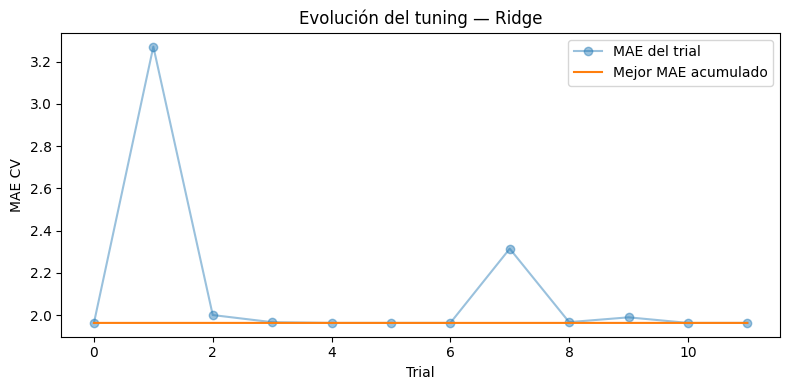

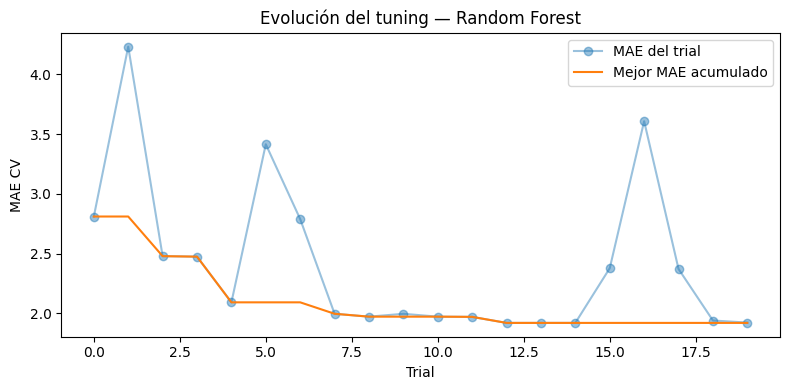

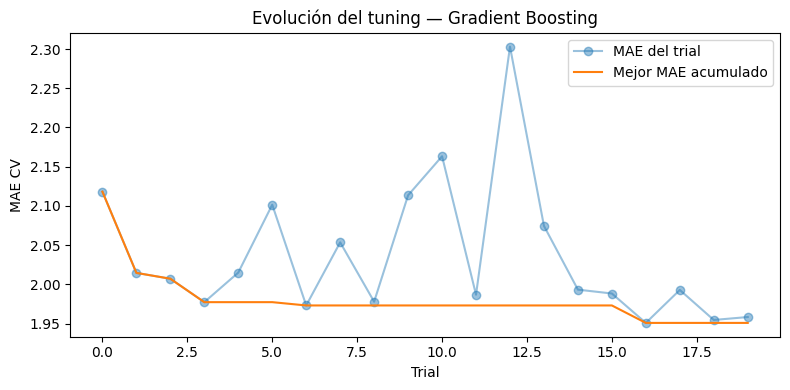

In [ ]:
estudios_optuna = {
    "Ridge": study_ridge,
    "Random Forest": study_rf,
    "Gradient Boosting": study_hgb
}

for nombre, estudio in estudios_optuna.items():

    trials_df = estudio.trials_dataframe()

    valores = trials_df[
        "value"
    ].astype(float)

    mejor_acumulado = valores.cummin()

    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        trials_df["number"],
        valores,
        marker="o",
        alpha=0.45,
        label="MAE del trial"
    )

    plt.plot(
        trials_df["number"],
        mejor_acumulado,
        label="Mejor MAE acumulado"
    )

    plt.xlabel(
        "Trial"
    )

    plt.ylabel(
        "MAE CV"
    )

    plt.title(
        f"Evolución del tuning — {nombre}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
for nombre, estudio in estudios_optuna.items():

    try:

        importancias_param = (
            optuna.importance
            .get_param_importances(
                estudio
            )
        )

        tabla_param = (
            pd.DataFrame(
                {
                    "Hiperparametro":
                        importancias_param.keys(),
                    "Importancia":
                        importancias_param.values()
                }
            )
            .sort_values(
                "Importancia",
                ascending=False
            )
        )

        print(
            "\nIMPORTANCIA DE HIPERPARÁMETROS:",
            nombre
        )

        display(
            tabla_param.round(4)
        )

    except Exception as e:

        print(
            nombre,
            "- no fue posible calcular la importancia:",
            e
        )



IMPORTANCIA DE HIPERPARÁMETROS: Ridge


,Hiperparametro,Importancia
0,alpha,1.0



IMPORTANCIA DE HIPERPARÁMETROS: Random Forest


,Hiperparametro,Importancia
0,n_estimators,0.7322
1,max_depth,0.0983
2,min_samples_leaf,0.0887
3,max_features,0.0808



IMPORTANCIA DE HIPERPARÁMETROS: Gradient Boosting


,Hiperparametro,Importancia
0,learning_rate,0.6907
1,max_leaf_nodes,0.2337
2,max_iter,0.0511
3,min_samples_leaf,0.0163
4,l2_regularization,0.0081


# 15. Selección final después del tuning

Ahora construimos los mejores modelos encontrados por Optuna y los volvemos a comparar bajo **el mismo protocolo de 5-fold cross-validation** utilizado anteriormente.

Compararemos:

- Regresión Lineal sin tuning;
- Ridge tuneado;
- Random Forest tuneado;
- Gradient Boosting tuneado.

Así evitamos elegir un modelo solo porque Optuna encontró una configuración prometedora.

## Principio de parsimonia

Si varios modelos quedan dentro del 1 % del mejor MAE, preferiremos el más sencillo e interpretable.

Solo abandonaremos la Regresión Lineal si un modelo más complejo demuestra una mejora suficientemente clara.

In [ ]:
ridge_tuneado = Ridge(
    **study_ridge.best_params
)

rf_tuneado = RandomForestRegressor(
    **study_rf.best_params,
    random_state=RANDOM_STATE,
    n_jobs=1
)

hgb_tuneado = HistGradientBoostingRegressor(
    **study_hgb.best_params,
    random_state=RANDOM_STATE
)

candidatos_finales = {
    "Regresión lineal":
        LinearRegression(),

    "Ridge tuneado":
        ridge_tuneado,

    "Random Forest tuneado":
        rf_tuneado,

    "Gradient Boosting tuneado":
        hgb_tuneado
}

resultados_finales_cv = []
pipelines_finales = {}

for nombre, reg in candidatos_finales.items():

    print(
        "Evaluando:",
        nombre
    )

    pipe = Pipeline([
        (
            "prep",
            crear_preprocesador(
                mejor_imputacion,
                mejor_scaler
            )
        ),
        (
            "reg",
            reg
        )
    ])

    pipelines_finales[
        nombre
    ] = pipe

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_modelos,
        scoring={
            "mae":
                "neg_mean_absolute_error",
            "rmse":
                "neg_root_mean_squared_error",
            "r2":
                "r2"
        },
        n_jobs=1
    )

    resultados_finales_cv.append({
        "Modelo": nombre,
        "MAE_CV":
            -scores[
                "test_mae"
            ].mean(),
        "MAE_std":
            scores[
                "test_mae"
            ].std(),
        "RMSE_CV":
            -scores[
                "test_rmse"
            ].mean(),
        "R2_CV":
            scores[
                "test_r2"
            ].mean(),
        "R2_std":
            scores[
                "test_r2"
            ].std()
    })


tabla_final_cv = (
    pd.DataFrame(
        resultados_finales_cv
    )
    .sort_values(
        "MAE_CV"
    )
    .reset_index(
        drop=True
    )
)

display(
    tabla_final_cv.round(4)
)

Evaluando: Regresión lineal
Evaluando: Ridge tuneado
Evaluando: Random Forest tuneado
Evaluando: Gradient Boosting tuneado


,Modelo,MAE_CV,MAE_std,RMSE_CV,R2_CV,R2_std
0,Random Forest tuneado,1.9011,0.1267,7.4092,0.6825,0.2741
1,Ridge tuneado,1.9487,0.1168,7.4102,0.6819,0.2745
2,Regresión lineal,1.9487,0.1168,7.4102,0.6819,0.2745
3,Gradient Boosting tuneado,1.9835,0.1193,7.4801,0.6774,0.2719


In [ ]:
mejor_mae_final = (
    tabla_final_cv[
        "MAE_CV"
    ].min()
)

finalistas = tabla_final_cv[
    tabla_final_cv[
        "MAE_CV"
    ]
    <= mejor_mae_final * 1.01
].copy()

prioridad_final = {
    "Regresión lineal": 1,
    "Ridge tuneado": 2,
    "Gradient Boosting tuneado": 3,
    "Random Forest tuneado": 4
}

finalistas[
    "Prioridad"
] = finalistas[
    "Modelo"
].map(
    prioridad_final
)

finalistas = (
    finalistas
    .sort_values(
        [
            "Prioridad",
            "MAE_CV"
        ]
    )
)

mejor_nombre = (
    finalistas
    .iloc[0][
        "Modelo"
    ]
)

mejor_modelo = (
    pipelines_finales[
        mejor_nombre
    ]
)

print(
    "Menor MAE después del tuning:",
    tabla_final_cv
    .iloc[0][
        "Modelo"
    ]
)

print(
    "Modelo FINAL por desempeño + parsimonia:",
    mejor_nombre
)

display(
    finalistas[
        [
            "Modelo",
            "MAE_CV",
            "RMSE_CV",
            "R2_CV"
        ]
    ].round(4)
)

Menor MAE después del tuning: Random Forest tuneado
Modelo FINAL por desempeño + parsimonia: Random Forest tuneado


,Modelo,MAE_CV,RMSE_CV,R2_CV
0,Random Forest tuneado,1.9011,7.4092,0.6825


### ¿Qué aprendemos del tuning?

Hay dos resultados posibles y ambos son válidos:

**Caso 1 — Un modelo tuneado mejora claramente**

Entonces la complejidad adicional puede estar justificada.

**Caso 2 — La mejora es mínima**

Entonces conservar un modelo sencillo es una decisión metodológicamente sólida.

El tuning no existe para obligarnos a cambiar de modelo. Existe para comprobar si una mejor configuración realmente aporta valor.

> El test todavía no se ha usado.

# 16. Evaluación final en test

Ahora, y solo ahora, utilizamos `X_test`.

El modelo seleccionado se entrena con todo `X_train` y se evalúa una sola vez sobre el test reservado.

In [ ]:
mejor_modelo.fit(
    X_train,
    y_train
)

pred_test = mejor_modelo.predict(
    X_test
)

mae_test = mean_absolute_error(
    y_test,
    pred_test
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_test,
        pred_test
    )
)

r2_test = r2_score(
    y_test,
    pred_test
)

print(
    "Modelo final:",
    mejor_nombre
)

print(
    f"MAE  test: {mae_test:.4f}"
)

print(
    f"RMSE test: {rmse_test:.4f}"
)

print(
    f"R²   test: {r2_test:.4f}"
)

Modelo final: Random Forest tuneado
MAE  test: 1.8110
RMSE test: 3.8457
R²   test: 0.8520


## 16.1 Comparación contra el baseline

Un buen modelo debe mejorar claramente al Dummy.

In [ ]:
dummy_final = Pipeline([
    (
        "prep",
        crear_preprocesador(
            mejor_imputacion,
            mejor_scaler
        )
    ),
    (
        "reg",
        DummyRegressor(
            strategy="mean"
        )
    )
])

dummy_final.fit(
    X_train,
    y_train
)

pred_dummy = dummy_final.predict(
    X_test
)

mae_dummy = mean_absolute_error(
    y_test,
    pred_dummy
)

mejora_dummy = (
    (mae_dummy - mae_test)
    / mae_dummy
    * 100
)

print(
    f"MAE Dummy : {mae_dummy:.4f}"
)

print(
    f"MAE modelo: {mae_test:.4f}"
)

print(
    f"Mejora frente al Dummy: {mejora_dummy:.2f}%"
)

MAE Dummy : 7.7620
MAE modelo: 1.8110
Mejora frente al Dummy: 76.67%


## 16.2 Real vs. predicho

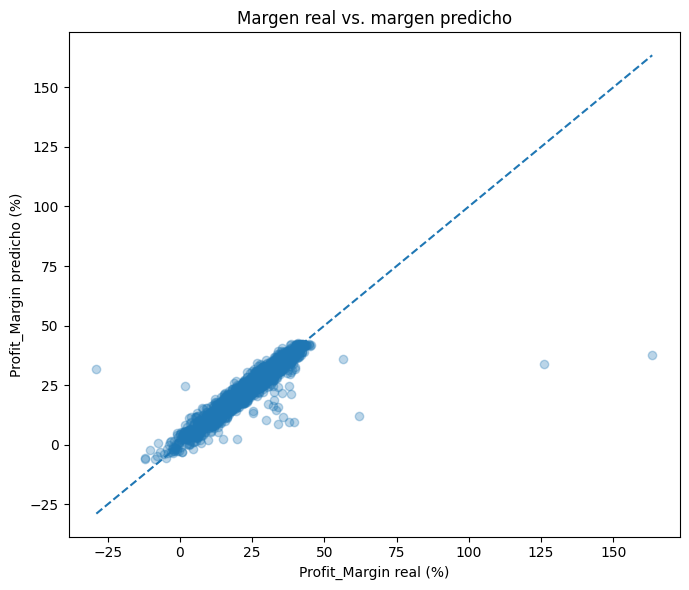

In [ ]:
plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    y_test,
    pred_test,
    alpha=0.30
)

lim_min = min(
    y_test.min(),
    pred_test.min()
)

lim_max = max(
    y_test.max(),
    pred_test.max()
)

plt.plot(
    [lim_min, lim_max],
    [lim_min, lim_max],
    linestyle="--"
)

plt.xlabel(
    "Profit_Margin real (%)"
)

plt.ylabel(
    "Profit_Margin predicho (%)"
)

plt.title(
    "Margen real vs. margen predicho"
)

plt.tight_layout()
plt.show()

## 16.3 Distribución de errores

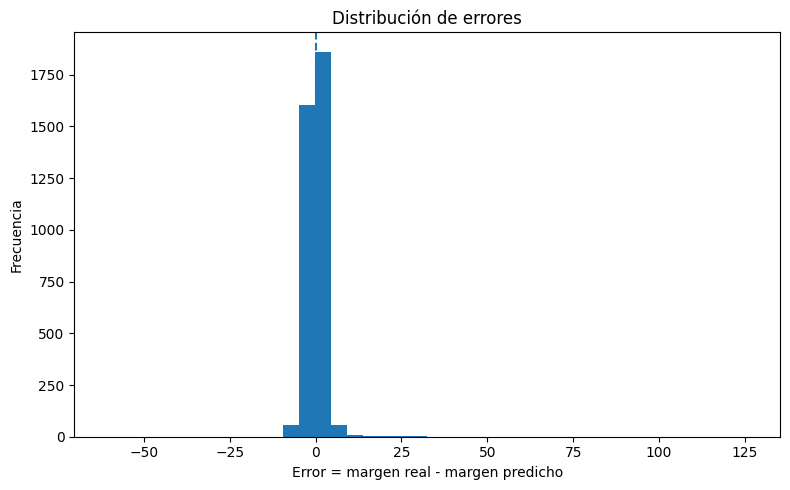

In [ ]:
residuos = (
    y_test.values
    - pred_test
)

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    residuos,
    bins=40
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Error = margen real - margen predicho"
)

plt.ylabel(
    "Frecuencia"
)

plt.title(
    "Distribución de errores"
)

plt.tight_layout()
plt.show()

# 17. Análisis de sensibilidad por inconsistencias financieras

El MAE, RMSE y R² del test mezclan dos fenómenos:

- el error real del modelo;
- y posibles errores o inconsistencias del dato financiero usado como target.

Por eso comparamos el desempeño en:

1. todo el test;
2. registros financieramente consistentes;
3. registros inconsistentes.

> **Importante:** no usamos esta comparación para borrar observaciones después de ver el test. Es un diagnóstico de calidad de datos.

In [ ]:
calidad_test = (
    df.loc[
        X_test.index,
        [
            "Transaction_ID",
            "Profit_Consistente",
            "Diferencia_Profit"
        ]
    ]
    .copy()
)

calidad_test[
    "Profit_Margin_real"
] = y_test.values

calidad_test[
    "Profit_Margin_pred"
] = pred_test

calidad_test[
    "Error_Absoluto"
] = np.abs(
    calidad_test["Profit_Margin_real"]
    - calidad_test["Profit_Margin_pred"]
)

print(
    "Filas consistentes en test:",
    calidad_test[
        "Profit_Consistente"
    ].sum()
)

print(
    "Filas inconsistentes en test:",
    (
        ~calidad_test[
            "Profit_Consistente"
        ]
    ).sum()
)

Filas consistentes en test: 3582
Filas inconsistentes en test: 18


In [ ]:
resultados_calidad = []

for nombre, mask in {
    "Test completo":
        np.ones(
            len(calidad_test),
            dtype=bool
        ),

    "Solo registros consistentes":
        calidad_test[
            "Profit_Consistente"
        ].values,

    "Solo registros inconsistentes":
        (
            ~calidad_test[
                "Profit_Consistente"
            ]
        ).values
}.items():

    y_real_grupo = calidad_test.loc[
        mask,
        "Profit_Margin_real"
    ]

    y_pred_grupo = calidad_test.loc[
        mask,
        "Profit_Margin_pred"
    ]

    if len(y_real_grupo) == 0:
        continue

    fila = {
        "Grupo": nombre,
        "N": len(y_real_grupo),
        "MAE": mean_absolute_error(
            y_real_grupo,
            y_pred_grupo
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_real_grupo,
                y_pred_grupo
            )
        )
    }

    if len(y_real_grupo) >= 2:

        fila["R2"] = r2_score(
            y_real_grupo,
            y_pred_grupo
        )

    else:

        fila["R2"] = np.nan

    resultados_calidad.append(
        fila
    )


tabla_calidad = pd.DataFrame(
    resultados_calidad
)

display(
    tabla_calidad.round(4)
)

,Grupo,N,MAE,RMSE,R2
0,Test completo,3600,1.8110,3.8457,0.8520
1,Solo registros consistentes,3582,1.6905,2.3500,0.9388
2,Solo registros inconsistentes,18,25.8005,43.1145,-0.0422


## Cómo interpretar esta tabla

Si los registros inconsistentes presentan errores mucho mayores, una parte de la pérdida de desempeño no proviene necesariamente de que el modelo no haya aprendido el patrón, sino de que el target contiene observaciones difíciles de reconciliar financieramente.

Esta diferencia debe reportarse como **limitación de calidad de datos**, no como una excusa para eliminar casos después de conocer el resultado.

# 17A. Data drift y similitud de distribuciones

Después de completar la evaluación final en test agregamos diagnósticos de distribución.

Estos análisis **no se utilizan para escoger el modelo**.

## 17A.1 PSI — Population Stability Index

Comparamos:

- referencia: 2022–2024;
- periodo reciente: 2025.

Regla práctica usada para lectura:

- PSI < 0.10 → cambio pequeño;
- 0.10–0.25 → cambio moderado;
- > 0.25 → cambio importante.

Además mostramos el cambio en porcentaje de faltantes.

El objetivo es detectar variables cuya distribución haya cambiado con el tiempo.


In [ ]:
def calcular_psi(
    referencia,
    actual,
    bins=10
):

    ref_s = pd.Series(
        referencia
    )

    act_s = pd.Series(
        actual
    )

    # Numérica continua
    if (
        pd.api.types.is_numeric_dtype(
            ref_s
        )
        and ref_s.nunique(
            dropna=True
        ) > bins
    ):

        ref_num = ref_s.dropna()
        act_num = act_s.dropna()

        if (
            len(ref_num) == 0
            or len(act_num) == 0
        ):
            return np.nan

        cortes = np.unique(
            np.quantile(
                ref_num,
                np.linspace(
                    0,
                    1,
                    bins + 1
                )
            )
        )

        if len(cortes) < 3:
            return 0.0

        cortes[0] = -np.inf
        cortes[-1] = np.inf

        ref_dist = (
            pd.cut(
                ref_num,
                cortes,
                include_lowest=True
            )
            .value_counts(
                normalize=True,
                sort=False
            )
        )

        act_dist = (
            pd.cut(
                act_num,
                cortes,
                include_lowest=True
            )
            .value_counts(
                normalize=True,
                sort=False
            )
            .reindex(
                ref_dist.index,
                fill_value=0
            )
        )

    else:

        ref_cat = (
            ref_s
            .fillna("__MISSING__")
            .astype(str)
        )

        act_cat = (
            act_s
            .fillna("__MISSING__")
            .astype(str)
        )

        categorias = sorted(
            set(ref_cat)
            | set(act_cat)
        )

        ref_dist = (
            ref_cat
            .value_counts(
                normalize=True
            )
            .reindex(
                categorias,
                fill_value=0
            )
        )

        act_dist = (
            act_cat
            .value_counts(
                normalize=True
            )
            .reindex(
                categorias,
                fill_value=0
            )
        )

    ref_dist = ref_dist.clip(
        lower=1e-4
    )

    act_dist = act_dist.clip(
        lower=1e-4
    )

    return float(
        (
            (act_dist - ref_dist)
            * np.log(
                act_dist / ref_dist
            )
        ).sum()
    )


year_numeric = pd.to_numeric(
    df["Order_Year"],
    errors="coerce"
)

mask_ref = (
    year_numeric <= 2024
)

mask_rec = (
    year_numeric == 2025
)

variables_drift = [
    v for v in features
    if v != "Order_Year"
]

filas_psi = []

for variable in (
    variables_drift
    + [target]
):

    valor_psi = calcular_psi(
        df.loc[
            mask_ref,
            variable
        ],
        df.loc[
            mask_rec,
            variable
        ]
    )

    falt_ref = (
        df.loc[
            mask_ref,
            variable
        ]
        .isna()
        .mean()
        * 100
    )

    falt_rec = (
        df.loc[
            mask_rec,
            variable
        ]
        .isna()
        .mean()
        * 100
    )

    if pd.isna(valor_psi):
        lectura = "sin cálculo"
    elif valor_psi < 0.10:
        lectura = "cambio pequeño"
    elif valor_psi < 0.25:
        lectura = "cambio moderado"
    else:
        lectura = "cambio importante"

    filas_psi.append({
        "Variable": variable,
        "PSI_2022_24_vs_2025":
            valor_psi,
        "%NaN_2022_24":
            falt_ref,
        "%NaN_2025":
            falt_rec,
        "Lectura":
            lectura
    })


tabla_psi = (
    pd.DataFrame(
        filas_psi
    )
    .sort_values(
        "PSI_2022_24_vs_2025",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    tabla_psi.round(4)
)


,Variable,PSI_2022_24_vs_2025,%NaN_2022_24,%NaN_2025,Lectura
0,Customer_Segment,0.7931,0.0000,0.0000,cambio importante
1,Product_Name,0.0176,0.7751,0.8654,cambio pequeño
2,Promotion_Code,0.0034,0.0000,0.0000,cambio pequeño
3,Unit_Price,0.0030,0.0000,0.0000,cambio pequeño
4,Age_Group,0.0020,1.2585,1.1069,cambio pequeño
5,Order_Quarter,0.0017,0.0000,0.0000,cambio pequeño
6,Profit_Margin,0.0016,0.0000,0.0000,cambio pequeño
7,Product_Category,0.0016,0.0000,0.0000,cambio pequeño
8,Inventory_Level,0.0016,1.0820,1.1471,cambio pequeño
9,Country,0.0013,0.0000,0.0000,cambio pequeño


### Cómo leer PSI

Un PSI alto no significa automáticamente que el modelo esté mal.

Significa:

> “La distribución de esta variable cambió entre el periodo histórico y 2025.”

Después debemos preguntar dos cosas:

1. ¿esa variable es importante para el modelo?;
2. ¿el desempeño temporal también se deteriora?

Por eso PSI se interpreta junto con importancia de variables y validación temporal.


## 17A.2 Validación adversarial: ¿train y test son distinguibles?

Construimos un problema auxiliar:

- `0` = fila que viene de train;
- `1` = fila que viene de test.

Un clasificador intenta distinguirlas usando solamente `X`.

Interpretación:

- AUC cercana a 0.5 → train y test son difíciles de distinguir;
- AUC alta → existe una diferencia estructural entre sus distribuciones.

Este diagnóstico **no usa `y_test`** y no cambia el modelo final.


In [ ]:
X_adv = pd.concat(
    [
        X_train,
        X_test
    ],
    axis=0
)

y_adv = np.concatenate([
    np.zeros(
        len(X_train),
        dtype=int
    ),
    np.ones(
        len(X_test),
        dtype=int
    )
])

pipe_adv = Pipeline([
    (
        "prep",
        crear_preprocesador(
            mejor_imputacion,
            mejor_scaler
        )
    ),
    (
        "clf",
        HistGradientBoostingClassifier(
            random_state=RANDOM_STATE
        )
    )
])

cv_adv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

auc_adv = cross_val_score(
    pipe_adv,
    X_adv,
    y_adv,
    cv=cv_adv,
    scoring="roc_auc",
    n_jobs=1
).mean()

print(
    "AUC validación adversarial:",
    round(
        auc_adv,
        4
    )
)

print(
    "Referencia: 0.5 significa que train y test "
    "son prácticamente indistinguibles."
)


AUC validación adversarial: 0.4903
Referencia: 0.5 significa que train y test son prácticamente indistinguibles.


# 17B. Validación temporal — entrenar con pasado y evaluar en 2025

El split aleatorio es útil para comparar modelos bajo las mismas condiciones.

Pero tenemos una pregunta adicional:

> **¿El modelo sigue funcionando si aprende del pasado y se enfrenta al año más reciente?**

Hacemos un experimento independiente:

- entrenamiento: 2022–2024;
- evaluación: 2025.

Este resultado es un **stress-test temporal**.

No se utiliza para volver atrás y escoger otro modelo.


In [ ]:
year_numeric = pd.to_numeric(
    df["Order_Year"],
    errors="coerce"
)

mask_hist = (
    year_numeric <= 2024
)

mask_2025 = (
    year_numeric == 2025
)

X_hist = X.loc[
    mask_hist
]

y_hist = y.loc[
    mask_hist
]

X_2025 = X.loc[
    mask_2025
]

y_2025 = y.loc[
    mask_2025
]

modelo_temporal = clone(
    mejor_modelo
)

modelo_temporal.fit(
    X_hist,
    y_hist
)

pred_2025 = modelo_temporal.predict(
    X_2025
)

mae_2025 = mean_absolute_error(
    y_2025,
    pred_2025
)

rmse_2025 = np.sqrt(
    mean_squared_error(
        y_2025,
        pred_2025
    )
)

r2_2025 = r2_score(
    y_2025,
    pred_2025
)

comparacion_temporal = pd.DataFrame([
    {
        "Evaluacion":
            "Test aleatorio 20%",
        "MAE":
            mae_test,
        "RMSE":
            rmse_test,
        "R2":
            r2_test
    },
    {
        "Evaluacion":
            "Train 2022-2024 → Test 2025",
        "MAE":
            mae_2025,
        "RMSE":
            rmse_2025,
        "R2":
            r2_2025
    }
])

display(
    comparacion_temporal.round(4)
)


,Evaluacion,MAE,RMSE,R2
0,Test aleatorio 20%,1.8110,3.8457,0.8520
1,Train 2022-2024 → Test 2025,2.0452,15.7364,0.2492


### Interpretación temporal

Si 2025 mantiene métricas cercanas al test aleatorio:

> tenemos evidencia adicional de que el patrón aprendido se mantiene hacia adelante en el tiempo.

Si empeora mucho:

> no significa necesariamente que el modelo esté “mal”; puede indicar estacionalidad, drift, cambios comerciales o diferencias entre años que deben estudiarse.

La validación temporal es especialmente valiosa si el modelo se quisiera usar en producción para ventas futuras.


# 18. ¿Demasiado bueno para ser verdad?

Si obtenemos un R² extraordinariamente alto o un MAE muy pequeño, no debemos celebrarlo inmediatamente.

Primero revisamos dos posibilidades:

1. fuga de información;
2. una estructura del negocio que haga el target altamente predecible.

Ya verificamos que `X` no contiene las variables que construyen directamente el margen.

Ahora usamos `Cost_Amount` y `Gross_Sales` **solo como diagnóstico posterior**, nunca como predictores.

La pregunta es:

> ¿Dentro de cada producto el costo relativo es casi constante?

Si lo es, entonces producto + descuento pueden contener una señal muy fuerte sobre el margen.

In [ ]:
print(
    "Leakage dentro de X:",
    sorted(
        set(features).intersection(
            leakage_columns
        )
    )
)

if {
    "Cost_Amount",
    "Gross_Sales",
    "Product_Name"
}.issubset(df.columns):

    diagnostico = df.copy()

    diagnostico[
        "Costo_Relativo"
    ] = np.where(
        diagnostico["Gross_Sales"].ne(0),
        diagnostico["Cost_Amount"]
        / diagnostico["Gross_Sales"],
        np.nan
    )

    estructura_producto = (
        diagnostico
        .groupby("Product_Name")[
            "Costo_Relativo"
        ]
        .agg(
            ["mean", "std", "count"]
        )
        .sort_values("std")
    )

    print(
        "\nDesviación estándar mediana "
        "del costo relativo por producto:",
        round(
            estructura_producto[
                "std"
            ].median(),
            4
        )
    )

    display(
        estructura_producto.head(30).round(4)
    )

Leakage dentro de X: []

Desviación estándar mediana del costo relativo por producto: 0.0184


,mean,std,count
Product_Name,,,
Premium Pens,0.5807,0.0141,832
Desk Lamp,0.6096,0.0151,671
Precision Mouse,0.6208,0.0157,903
USB Power Hub,0.6400,0.0159,880
Notebook Pack,0.6293,0.0159,886
Ergo Footrest,0.6399,0.0160,707
Presentation Kit,0.6697,0.0162,565
NoiseCancel Headset,0.6901,0.0166,710
SmartDock USB-C,0.7092,0.0175,623


# 19. Importancia por permutación

La pregunta de negocio exige algo más que precisión.

Queremos saber:

> **¿Qué variables pierden más capacidad predictiva cuando las desordenamos?**

La importancia por permutación:

1. calcula el desempeño normal;
2. desordena una variable;
3. vuelve a medir el MAE;
4. si el MAE aumenta mucho, esa variable era importante.

Esto funciona sobre las **variables originales**, antes del One-Hot, y es mucho más fácil de interpretar para negocio.

In [ ]:
perm = permutation_importance(
    mejor_modelo,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=8,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importancias = pd.DataFrame({
    "Variable": X_test.columns,
    "Aumento_MAE": perm.importances_mean,
    "Desviacion": perm.importances_std
})

importancias = (
    importancias
    .sort_values(
        "Aumento_MAE",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    importancias.round(4)
)

,Variable,Aumento_MAE,Desviacion
0,Unit_Price,5.1230,0.0838
1,Discount_Percentage,4.8236,0.0690
2,Product_Name,1.7448,0.0163
3,Product_Category,0.6718,0.0282
4,Day_of_Week,0.0025,0.0032
5,Inventory_Level,0.0024,0.0052
6,Promotion_Code,0.0011,0.0028
7,Age_Group,0.0010,0.0014
8,Country,0.0004,0.0017
9,Customer_Gender,0.0001,0.0009


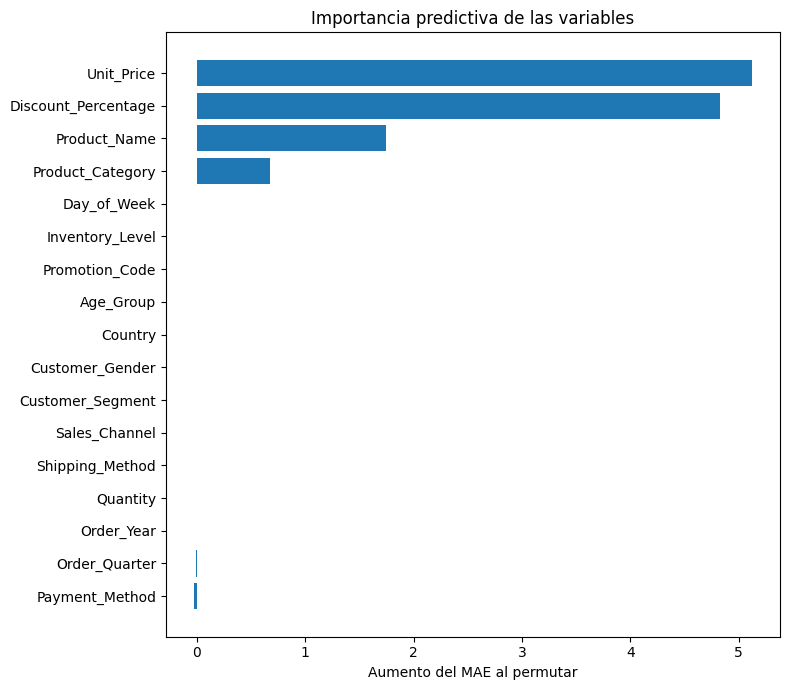

In [ ]:
plt.figure(
    figsize=(8, 7)
)

imp_plot = (
    importancias
    .sort_values(
        "Aumento_MAE"
    )
)

plt.barh(
    imp_plot["Variable"],
    imp_plot["Aumento_MAE"]
)

plt.xlabel(
    "Aumento del MAE al permutar"
)

plt.title(
    "Importancia predictiva de las variables"
)

plt.tight_layout()
plt.show()

# 19A. SHAP — interpretar dirección y predicciones individuales

La importancia por permutación responde:

> **¿Cuánto empeora el modelo si destruyo la información de una variable?**

SHAP responde algo diferente:

> **¿Cuánto contribuyó cada variable a subir o bajar una predicción concreta?**

Para regresión:

- SHAP positivo → empuja el margen predicho hacia arriba;
- SHAP negativo → empuja el margen predicho hacia abajo.

Usaremos:

- explicación global;
- importancia SHAP agregada por variable original;
- relación SHAP del descuento;
- explicación local de una venta con margen predicho bajo y una con margen predicho alto.

> SHAP explica al modelo. No demuestra causalidad.


In [ ]:
# SHAP puede no venir instalado por defecto.
import sys
import subprocess
import importlib

if importlib.util.find_spec(
    "shap"
) is None:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "shap"
    ])

import shap

print(
    "SHAP listo."
)


SHAP listo.


In [ ]:
prep_shap = (
    mejor_modelo
    .named_steps[
        "prep"
    ]
)

reg_shap = (
    mejor_modelo
    .named_steps[
        "reg"
    ]
)

nombres_shap = (
    prep_shap
    .get_feature_names_out()
)

X_shap = X_test.sample(
    n=min(
        800,
        len(X_test)
    ),
    random_state=RANDOM_STATE
)

X_background = X_train.sample(
    n=min(
        800,
        len(X_train)
    ),
    random_state=RANDOM_STATE
)

X_shap_prep = pd.DataFrame(
    prep_shap.transform(
        X_shap
    ),
    columns=nombres_shap,
    index=X_shap.index
)

X_background_prep = pd.DataFrame(
    prep_shap.transform(
        X_background
    ),
    columns=nombres_shap,
    index=X_background.index
)

if isinstance(
    reg_shap,
    (
        LinearRegression,
        Ridge
    )
):

    explainer_shap = (
        shap.LinearExplainer(
            reg_shap,
            shap.maskers.Independent(
                X_background_prep,
                max_samples=500
            )
        )
    )

    valores_shap = (
        explainer_shap(
            X_shap_prep
        )
    )

else:

    try:

        explainer_shap = (
            shap.TreeExplainer(
                reg_shap
            )
        )

        valores_shap = (
            explainer_shap(
                X_shap_prep
            )
        )

    except Exception:

        # Fallback más general.
        # Usamos una muestra menor porque puede ser más costoso.
        X_shap_prep = (
            X_shap_prep
            .iloc[:250]
        )

        X_shap = X_shap.loc[
            X_shap_prep.index
        ]

        explainer_shap = shap.Explainer(
            reg_shap.predict,
            X_background_prep.iloc[:300]
        )

        valores_shap = explainer_shap(
            X_shap_prep
        )


print(
    "Explainer:",
    type(
        explainer_shap
    ).__name__
)

print(
    "Forma SHAP:",
    valores_shap.values.shape
)


Explainer: TreeExplainer
Forma SHAP: (800, 92)


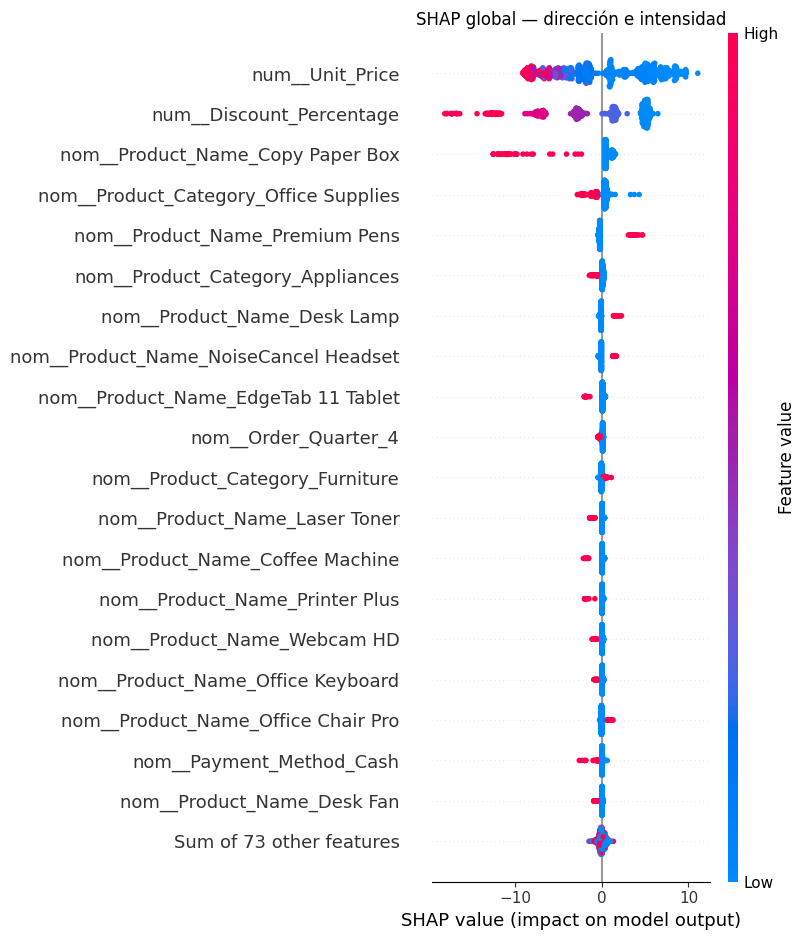

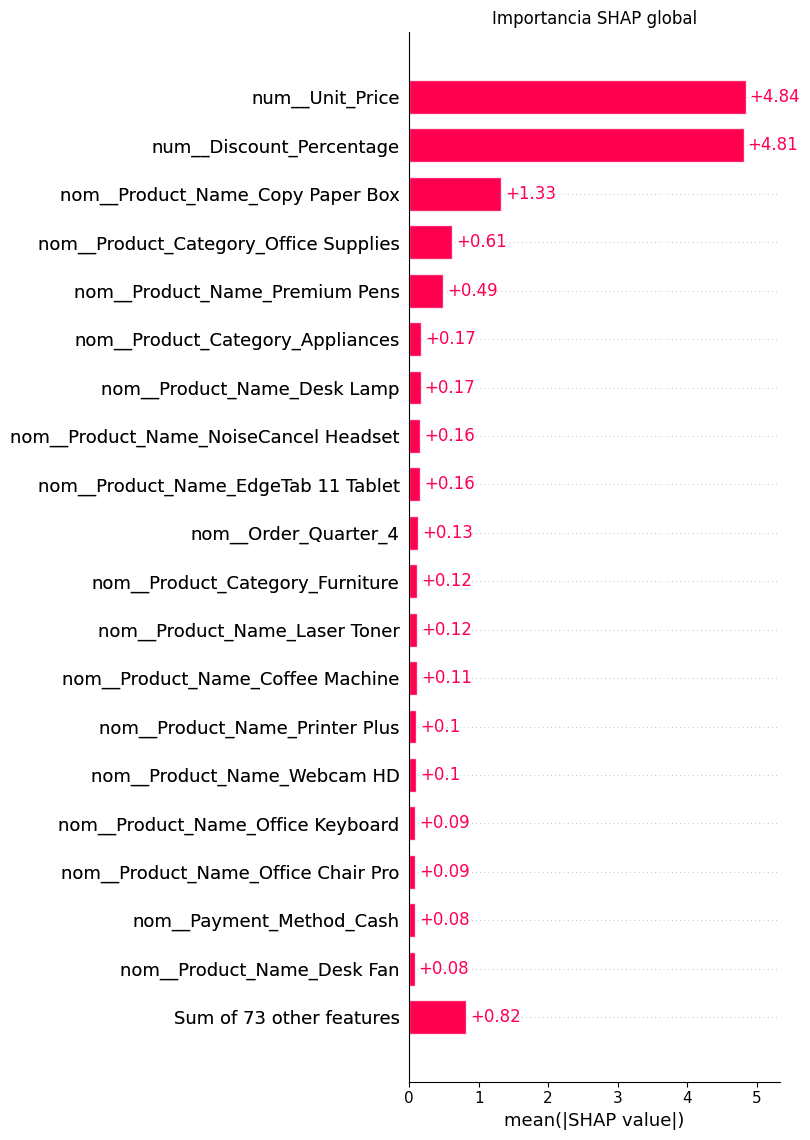

In [ ]:
# Visión global: variables transformadas

shap.plots.beeswarm(
    valores_shap,
    max_display=20,
    show=False
)

plt.title(
    "SHAP global — dirección e intensidad"
)

plt.tight_layout()
plt.show()


shap.plots.bar(
    valores_shap,
    max_display=20,
    show=False
)

plt.title(
    "Importancia SHAP global"
)

plt.tight_layout()
plt.show()


In [ ]:
def variable_original_desde_shap(
    nombre_transformado
):

    limpio = (
        nombre_transformado
        .split(
            "__",
            1
        )[-1]
    )

    for variable in sorted(
        features,
        key=len,
        reverse=True
    ):

        if (
            limpio == variable
            or limpio.startswith(
                variable + "_"
            )
            or variable in limpio
        ):
            return variable

    return limpio


mapa_shap_original = {
    nombre:
        variable_original_desde_shap(
            nombre
        )
    for nombre in nombres_shap
}

shap_abs = pd.Series(
    np.abs(
        valores_shap.values
    ).mean(
        axis=0
    ),
    index=nombres_shap
)

shap_por_variable = (
    shap_abs
    .groupby(
        mapa_shap_original
    )
    .sum()
    .sort_values(
        ascending=False
    )
    .rename(
        "SHAP_medio_absoluto"
    )
)

display(
    shap_por_variable
    .head(20)
    .to_frame()
    .round(4)
)


,SHAP_medio_absoluto
Unit_Price,4.8418
Discount_Percentage,4.8127
Product_Name,3.2880
Product_Category,0.9545
Order_Quarter,0.1550
Payment_Method,0.1195
Customer_Segment,0.0594
Day_of_Week,0.0591
Promotion_Code,0.0491
Inventory_Level,0.0444


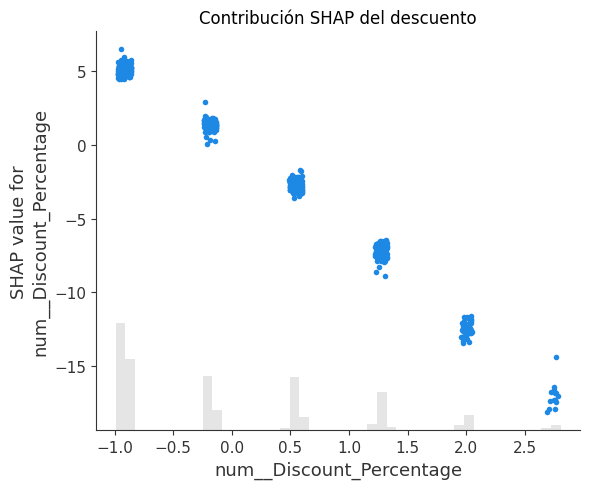

In [ ]:
# Efecto del descuento en el modelo

columnas_descuento = [
    i
    for i, nombre in enumerate(
        nombres_shap
    )
    if "Discount_Percentage" in nombre
]

if len(
    columnas_descuento
) > 0:

    idx_desc = (
        columnas_descuento[0]
    )

    shap.plots.scatter(
        valores_shap[
            :,
            idx_desc
        ],
        show=False
    )

    plt.title(
        "Contribución SHAP del descuento"
    )

    plt.tight_layout()
    plt.show()



=== MARGEN PREDICHO BAJO ===
Margen predicho: -2.6 %
Margen real: -0.43 %
Producto: Copy Paper Box
Descuento: 20.0 %
Precio: 44.43


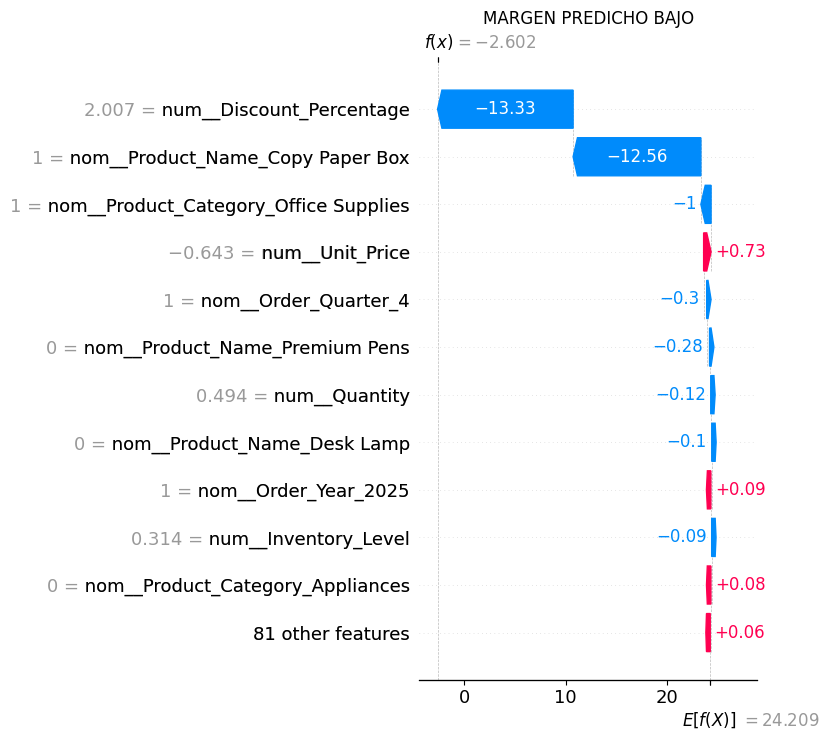


=== MARGEN PREDICHO ALTO ===
Margen predicho: 42.11 %
Margen real: 40.08 %
Producto: Premium Pens
Descuento: 0.0 %
Precio: 23.46


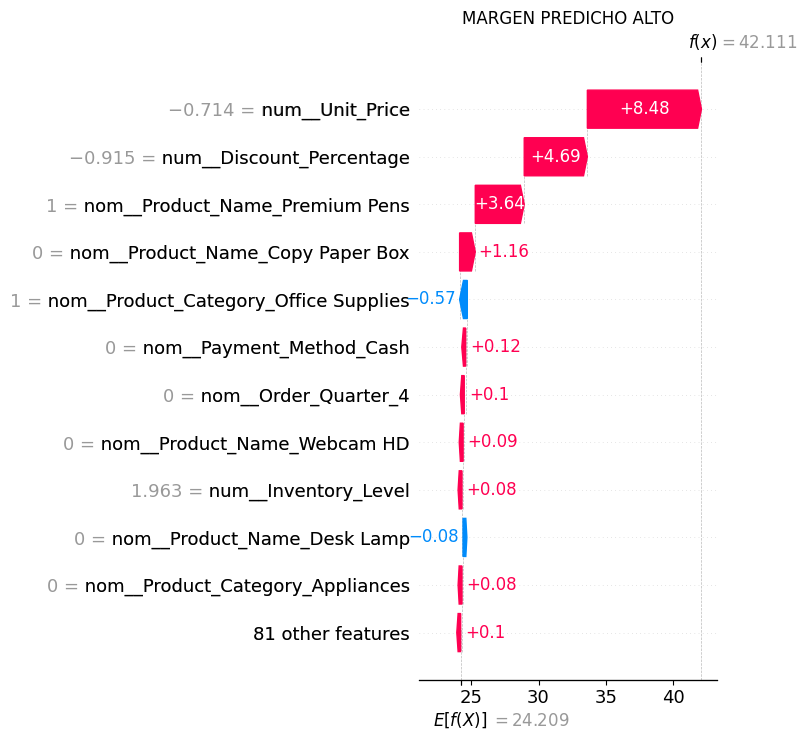

In [ ]:
# Explicaciones locales:
# una transacción con margen predicho bajo
# y otra con margen predicho alto.

pred_shap = mejor_modelo.predict(
    X_shap
)

idx_bajo = int(
    np.argmin(
        pred_shap
    )
)

idx_alto = int(
    np.argmax(
        pred_shap
    )
)

for posicion, etiqueta in [
    (
        idx_bajo,
        "MARGEN PREDICHO BAJO"
    ),
    (
        idx_alto,
        "MARGEN PREDICHO ALTO"
    )
]:

    indice_real = (
        X_shap
        .index[
            posicion
        ]
    )

    fila = X_shap.iloc[
        posicion
    ]

    print(
        "\n===",
        etiqueta,
        "==="
    )

    print(
        "Margen predicho:",
        round(
            pred_shap[
                posicion
            ],
            2
        ),
        "%"
    )

    print(
        "Margen real:",
        round(
            y_test.loc[
                indice_real
            ],
            2
        ),
        "%"
    )

    print(
        "Producto:",
        fila[
            "Product_Name"
        ]
    )

    print(
        "Descuento:",
        fila[
            "Discount_Percentage"
        ],
        "%"
    )

    print(
        "Precio:",
        fila[
            "Unit_Price"
        ]
    )

    shap.plots.waterfall(
        valores_shap[
            posicion
        ],
        max_display=12,
        show=False
    )

    plt.title(
        etiqueta
    )

    plt.tight_layout()
    plt.show()


### SHAP vs. permutation importance

No son técnicas rivales.

- **Permutation importance** → mide cuánto necesita el modelo una variable para mantener su desempeño.
- **SHAP** → muestra cuánto y en qué dirección contribuye cada valor a las predicciones.

Si ambas técnicas destacan las mismas variables principales, la interpretación gana consistencia.

Si difieren, debemos analizar por qué: correlación entre variables, codificación One-Hot, no linealidades o interacciones pueden producir rankings distintos.



# 19B. Bloque diferencial — margen esperado según la estructura económica

Hasta ahora sabemos qué variables son importantes para predecir.

Ahora formulamos una pregunta adicional:

> **Después de considerar producto, precio, descuento y demás condiciones económicas básicas, ¿siguen apareciendo diferencias por cliente, canal o periodo?**

Para responder construimos un **modelo de ajuste**, separado del modelo final.

Este modelo utiliza únicamente:

### Condiciones de la venta
- `Discount_Percentage`
- `Unit_Price`
- `Quantity`
- `Inventory_Level`

### Producto
- `Product_Name`
- `Product_Category`

El objetivo NO es reemplazar el modelo final.

Su función es estimar:

`margen esperado según la estructura económica`

Utilizamos predicciones **out-of-fold (OOF)** para que el margen esperado de una fila sea producido por un modelo que no fue entrenado con esa misma fila.


In [ ]:

variables_economicas_num = [
    c
    for c in [
        "Discount_Percentage",
        "Unit_Price",
        "Quantity",
        "Inventory_Level"
    ]
    if c in df.columns
]

variables_economicas_cat = [
    c
    for c in [
        "Product_Name",
        "Product_Category"
    ]
    if c in df.columns
]

variables_economicas = (
    variables_economicas_num
    + variables_economicas_cat
)

prep_economico = ColumnTransformer([
    (
        "num",
        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]),
        variables_economicas_num
    ),
    (
        "cat",
        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]),
        variables_economicas_cat
    )
])

modelo_economico = Pipeline([
    (
        "prep",
        prep_economico
    ),
    (
        "reg",
        Ridge(
            alpha=10.0
        )
    )
])

cv_ajuste = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

pred_oof_economico = cross_val_predict(
    modelo_economico,
    df[
        variables_economicas
    ],
    y,
    cv=cv_ajuste,
    n_jobs=1
)

df[
    "Margen_Esperado_OOF"
] = pred_oof_economico

df[
    "Residuo_Ajustado"
] = (
    df[target]
    - df[
        "Margen_Esperado_OOF"
    ]
)

print(
    "Modelo económico OOF"
)

print(
    "MAE:",
    round(
        mean_absolute_error(
            y,
            pred_oof_economico
        ),
        4
    )
)

print(
    "R²:",
    round(
        r2_score(
            y,
            pred_oof_economico
        ),
        4
    )
)


Modelo económico OOF
MAE: 1.8699
R²: 0.5223



## ¿Qué significa `Residuo_Ajustado`?

Se calcula como:

`Margen real - Margen esperado según producto y condiciones de venta`

Ejemplo:

- margen real = 24 %
- margen esperado = 20 %
- residuo ajustado = +4 puntos

Interpretación:

> esa transacción quedó 4 puntos porcentuales por encima de lo esperado según su estructura económica.

Si el residuo es negativo:

> quedó por debajo de lo esperado.

Este residuo permite estudiar cliente, canal y periodo **después de descontar estadísticamente parte de la estructura de producto y venta**.

Sigue siendo un análisis asociativo, no causal.



# 19C. Asociación cruda vs. asociación ajustada

Para cada nivel de variables de:

- cliente;
- canal;
- periodo;

mostramos dos lecturas:

### Margen crudo
El margen agregado observado directamente.

### Efecto ajustado
El promedio de `Residuo_Ajustado`.

Si una diferencia grande en margen crudo se acerca a cero después del ajuste:

> parte importante de esa diferencia parece explicarse por la mezcla de productos y condiciones comerciales.

Si permanece claramente alejada de cero:

> existe una asociación adicional que el modelo económico base no absorbió completamente.


In [ ]:

variables_ajuste = [
    c
    for c in [
        "Sales_Channel",
        "Customer_Segment",
        "Age_Group",
        "Customer_Gender",
        "Country",
        "Payment_Method",
        "Shipping_Method",
        "Promotion_Code",
        "Order_Quarter",
        "Order_Year",
        "Day_of_Week"
    ]
    if c in df.columns
]

filas_ajuste = []

for variable in variables_ajuste:

    margen_crudo = (
        df
        .groupby(
            variable,
            dropna=False
        )
        .apply(
            margen_agregado
        )
        .rename(
            "Margen_crudo"
        )
    )

    ajustado = (
        df
        .groupby(
            variable,
            dropna=False
        )[
            "Residuo_Ajustado"
        ]
        .agg(
            [
                "mean",
                "count",
                "std"
            ]
        )
    )

    ajustado[
        "se"
    ] = (
        ajustado["std"]
        / np.sqrt(
            ajustado["count"]
        )
    )

    ajustado[
        "IC95_inf"
    ] = (
        ajustado["mean"]
        - 1.96
        * ajustado["se"]
    )

    ajustado[
        "IC95_sup"
    ] = (
        ajustado["mean"]
        + 1.96
        * ajustado["se"]
    )

    tabla_variable = (
        ajustado
        .join(
            margen_crudo
        )
        .reset_index()
        .rename(
            columns={
                variable:
                    "Nivel",
                "mean":
                    "Efecto_ajustado_pp"
            }
        )
    )

    tabla_variable[
        "Variable"
    ] = variable

    filas_ajuste.append(
        tabla_variable
    )


tabla_asociacion_ajustada = pd.concat(
    filas_ajuste,
    ignore_index=True
)

display(
    tabla_asociacion_ajustada[
        [
            "Variable",
            "Nivel",
            "Margen_crudo",
            "Efecto_ajustado_pp",
            "IC95_inf",
            "IC95_sup",
            "count"
        ]
    ]
    .round(3)
)


,Variable,Nivel,Margen_crudo,Efecto_ajustado_pp,IC95_inf,IC95_sup,count
0,Sales_Channel,B2B Portal,19.787,-0.028,-0.142,0.085,2124
1,Sales_Channel,Online,20.238,0.008,-0.255,0.271,8195
2,Sales_Channel,Phone Order,19.667,0.030,-0.304,0.364,1460
3,Sales_Channel,Retail Store,19.902,-0.009,-0.111,0.094,6221
4,Customer_Segment,Consumer,20.118,-0.017,-0.109,0.074,8027
...,...,...,...,...,...,...,...
58,Day_of_Week,Saturday,19.880,0.038,-0.095,0.171,1923
59,Day_of_Week,Sunday,20.213,-0.451,-1.476,0.574,1977
60,Day_of_Week,Thursday,20.345,0.126,-0.017,0.269,2844
61,Day_of_Week,Tuesday,19.944,0.152,-0.014,0.318,2838


In [ ]:

# Lectura específica de trimestre:
# sirve para conectar el EDA de Q4 con el análisis ajustado.

if "Order_Quarter" in variables_ajuste:

    tabla_q_ajustada = (
        tabla_asociacion_ajustada[
            tabla_asociacion_ajustada[
                "Variable"
            ] == "Order_Quarter"
        ]
        .copy()
    )

    print(
        "TRIMESTRE — MARGEN CRUDO VS EFECTO AJUSTADO"
    )

    display(
        tabla_q_ajustada[
            [
                "Nivel",
                "Margen_crudo",
                "Efecto_ajustado_pp",
                "IC95_inf",
                "IC95_sup",
                "count"
            ]
        ]
        .round(3)
    )


TRIMESTRE — MARGEN CRUDO VS EFECTO AJUSTADO


,Nivel,Margen_crudo,Efecto_ajustado_pp,IC95_inf,IC95_sup,count
48,1,21.368,-0.139,-0.714,0.437,3726
49,2,21.148,0.048,-0.039,0.134,4292
50,3,23.108,0.066,-0.079,0.210,4116
51,4,16.088,0.007,-0.080,0.094,5866



### Qué buscamos especialmente en Q4

En el EDA Q4 mostró menor margen.

Ahora observamos su `Efecto_ajustado_pp`.

- Si se acerca a **0** → el menor margen de Q4 se explica en gran medida por producto y condiciones de venta.
- Si sigue siendo claramente negativo → queda una asociación adicional de Q4 que la estructura económica básica no explica completamente.

Esto mejora la interpretación del EDA porque diferencia:

**asociación descriptiva**  
de  
**diferencia que permanece después del ajuste**.


# 20. Respuesta por dimensiones de negocio

Agrupamos las variables para volver a la pregunta original.

### Condiciones de la venta
Descuento, cantidad, precio e inventario.

### Producto
Nombre y categoría.

### Cliente
Segmento, edad, género y país.

### Canales
Canal, pago, envío y promoción.

### Periodos
Trimestre, año y día.

Las pequeñas importancias negativas producidas por ruido estadístico se llevan a cero antes de sumar.

In [ ]:
imp_map = (
    importancias
    .set_index("Variable")[
        "Aumento_MAE"
    ]
)

def importancia_dimension(lista):

    valores = [
        max(
            0,
            float(
                imp_map.get(
                    v,
                    0
                )
            )
        )
        for v in lista
    ]

    return sum(valores)


dimensiones = {
    "Condiciones de la venta": [
        "Discount_Percentage",
        "Quantity",
        "Unit_Price",
        "Inventory_Level"
    ],

    "Producto": [
        "Product_Name",
        "Product_Category"
    ],

    "Cliente": [
        "Customer_Segment",
        "Age_Group",
        "Customer_Gender",
        "Country"
    ],

    "Canales": [
        "Sales_Channel",
        "Payment_Method",
        "Shipping_Method",
        "Promotion_Code"
    ],

    "Periodos": [
        "Order_Quarter",
        "Order_Year",
        "Day_of_Week"
    ]
}


tabla_dimensiones = pd.DataFrame({
    "Dimension": dimensiones.keys(),
    "Importancia_Agregada": [
        importancia_dimension(
            variables
        )
        for variables in dimensiones.values()
    ]
})

tabla_dimensiones = (
    tabla_dimensiones
    .sort_values(
        "Importancia_Agregada",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    tabla_dimensiones.round(4)
)

,Dimension,Importancia_Agregada
0,Condiciones de la venta,9.9489
1,Producto,2.4166
2,Periodos,0.0025
3,Cliente,0.0015
4,Canales,0.0011


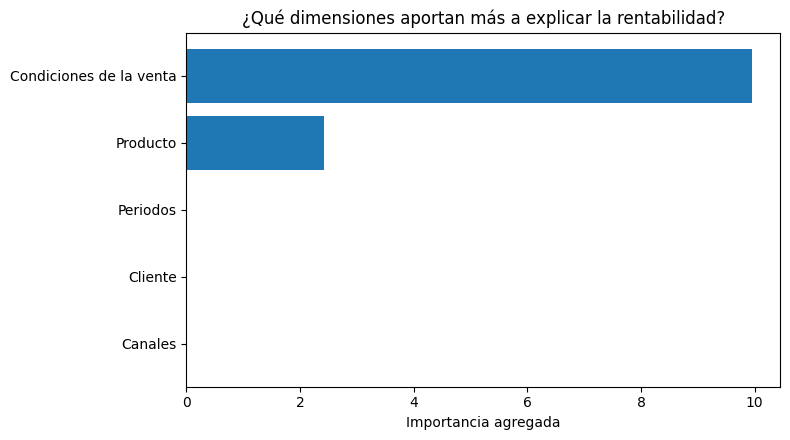

In [ ]:
plt.figure(
    figsize=(8, 4.5)
)

plot_dim = (
    tabla_dimensiones
    .sort_values(
        "Importancia_Agregada"
    )
)

plt.barh(
    plot_dim["Dimension"],
    plot_dim["Importancia_Agregada"]
)

plt.xlabel(
    "Importancia agregada"
)

plt.title(
    "¿Qué dimensiones aportan más a explicar la rentabilidad?"
)

plt.tight_layout()
plt.show()

## Cómo interpretar esta tabla

Si `Periodos` pierde importancia una vez que el modelo conoce producto y descuento, eso sugiere que el trimestre puede estar funcionando principalmente como **contexto donde cambian las políticas comerciales**, no necesariamente como un factor independiente.

Si `Cliente` o `Canales` tienen baja importancia, eso no significa que no sean importantes para ventas.

Puede significar que explican **volumen**, pero aportan poco para explicar la **eficiencia de margen**.

> Nuevamente: esto describe asociación predictiva, no causalidad.


# 20A. Capacidad predictiva por bloques de negocio

La suma de importancias individuales nos dice qué variables destacan.

Pero para responder la pregunta original también queremos evaluar dimensiones completas.

Definimos cinco bloques:

- **Venta:** descuento, cantidad, precio e inventario.
- **Producto:** nombre y categoría.
- **Cliente:** segmento, edad, género y país.
- **Canal:** canal de venta, pago, envío y promoción.
- **Periodo:** trimestre, año y día.

Para cada bloque hacemos dos preguntas:

### 1. ¿Qué puede explicar el bloque por sí solo?
Medimos MAE y R² usando únicamente esa dimensión.

### 2. ¿Cuánto perdemos al quitarlo?
Comparamos el modelo completo contra un modelo sin esa dimensión.

Este análisis se realiza con **predicciones out-of-fold dentro de train**.

Por eso no utiliza el test final para decidir qué dimensión es importante.


In [ ]:

bloques_negocio = {
    "Venta": [
        c
        for c in [
            "Discount_Percentage",
            "Quantity",
            "Unit_Price",
            "Inventory_Level"
        ]
        if c in features
    ],

    "Producto": [
        c
        for c in [
            "Product_Name",
            "Product_Category"
        ]
        if c in features
    ],

    "Cliente": [
        c
        for c in [
            "Customer_Segment",
            "Age_Group",
            "Customer_Gender",
            "Country"
        ]
        if c in features
    ],

    "Canal": [
        c
        for c in [
            "Sales_Channel",
            "Payment_Method",
            "Shipping_Method",
            "Promotion_Code"
        ]
        if c in features
    ],

    "Periodo": [
        c
        for c in [
            "Order_Quarter",
            "Order_Year",
            "Day_of_Week"
        ]
        if c in features
    ]
}

cols_bloques = []

for cols in bloques_negocio.values():

    for col in cols:

        if col not in cols_bloques:
            cols_bloques.append(
                col
            )


def modelo_para_bloque(
    columnas
):

    return Pipeline([
        (
            "prep",
            crear_preprocesador(
                mejor_imputacion,
                mejor_scaler,
                subset_features=columnas
            )
        ),
        (
            "reg",
            Ridge(
                alpha=10.0
            )
        )
    ])


def evaluar_bloque_oof(
    columnas
):

    pred = cross_val_predict(
        modelo_para_bloque(
            columnas
        ),
        X_train[
            columnas
        ],
        y_train,
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE
        ),
        n_jobs=1
    )

    return {
        "MAE":
            mean_absolute_error(
                y_train,
                pred
            ),
        "R2":
            r2_score(
                y_train,
                pred
            )
    }


metricas_full_bloques = (
    evaluar_bloque_oof(
        cols_bloques
    )
)

filas_bloques = []

for nombre, cols in bloques_negocio.items():

    solo = evaluar_bloque_oof(
        cols
    )

    columnas_sin = [
        c
        for c in cols_bloques
        if c not in cols
    ]

    sin_dimension = evaluar_bloque_oof(
        columnas_sin
    )

    filas_bloques.append({
        "Dimension":
            nombre,
        "N_variables":
            len(cols),
        "MAE_solo":
            solo["MAE"],
        "R2_solo":
            solo["R2"],
        "MAE_sin_dimension":
            sin_dimension["MAE"],
        "R2_sin_dimension":
            sin_dimension["R2"],
        "Aumento_MAE_al_quitar":
            (
                sin_dimension["MAE"]
                - metricas_full_bloques["MAE"]
            ),
        "Caida_R2_al_quitar":
            (
                metricas_full_bloques["R2"]
                - sin_dimension["R2"]
            )
    })


tabla_bloques = (
    pd.DataFrame(
        filas_bloques
    )
    .sort_values(
        "Aumento_MAE_al_quitar",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Modelo con todos los bloques"
)

print(
    "MAE OOF:",
    round(
        metricas_full_bloques["MAE"],
        4
    )
)

print(
    "R² OOF:",
    round(
        metricas_full_bloques["R2"],
        4
    )
)

display(
    tabla_bloques.round(4)
)


Modelo con todos los bloques
MAE OOF: 1.9729
R² OOF: 0.4719


,Dimension,N_variables,MAE_solo,R2_solo,MAE_sin_dimension,R2_sin_dimension,Aumento_MAE_al_quitar,Caida_R2_al_quitar
0,Producto,2,5.2604,0.2793,5.3102,0.2687,3.3373,0.2032
1,Venta,4,5.2747,0.2715,4.6041,0.3230,2.6312,0.1489
2,Cliente,4,7.8323,-0.0010,1.9563,0.4723,-0.0166,-0.0004
3,Periodo,3,7.5498,0.0432,1.9561,0.4726,-0.0168,-0.0007
4,Canal,4,7.8393,-0.0017,1.9462,0.4726,-0.0267,-0.0008


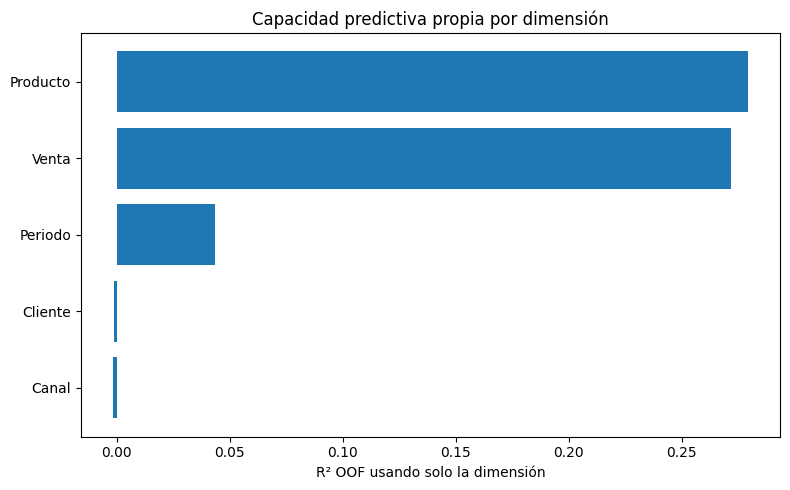

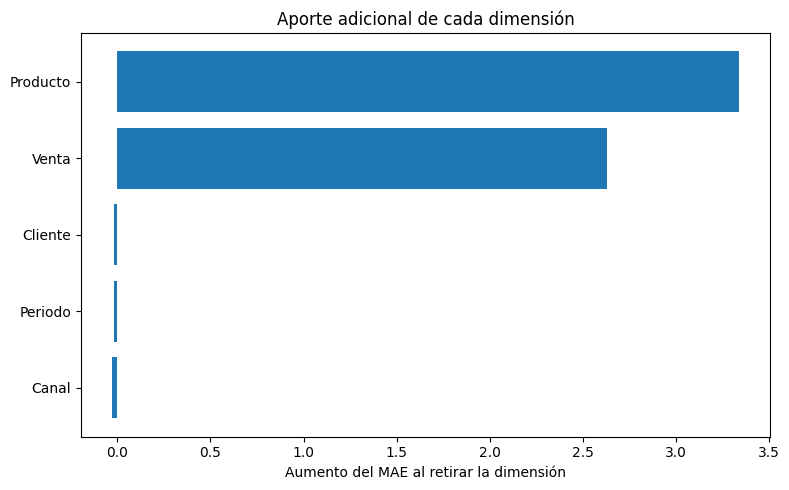

In [ ]:

plt.figure(
    figsize=(8, 5)
)

tabla_plot = (
    tabla_bloques
    .sort_values(
        "R2_solo"
    )
)

plt.barh(
    tabla_plot[
        "Dimension"
    ],
    tabla_plot[
        "R2_solo"
    ]
)

plt.xlabel(
    "R² OOF usando solo la dimensión"
)

plt.title(
    "Capacidad predictiva propia por dimensión"
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 5)
)

tabla_plot = (
    tabla_bloques
    .sort_values(
        "Aumento_MAE_al_quitar"
    )
)

plt.barh(
    tabla_plot[
        "Dimension"
    ],
    tabla_plot[
        "Aumento_MAE_al_quitar"
    ]
)

plt.xlabel(
    "Aumento del MAE al retirar la dimensión"
)

plt.title(
    "Aporte adicional de cada dimensión"
)

plt.tight_layout()
plt.show()



### Por qué usamos las dos lecturas

Una dimensión puede:

- funcionar bien sola;
- pero aportar poco cuando otras variables ya están presentes.

Ejemplo:

`Periodo` podría mostrar diferencias descriptivas por trimestre, pero si al quitarlo del modelo completo el MAE casi no cambia, entonces aporta poca información adicional una vez conocemos producto y condiciones de venta.

Eso es exactamente lo que queremos distinguir.



# 20B. Matriz de oportunidades — volumen vs. eficiencia ajustada

Una variable puede tener margen alto pero representar muy poco volumen.

Otra puede mover muchas ventas pero quedar por debajo del margen esperado.

Para conectar el análisis con negocio combinamos:

### Volumen
`Participacion_ventas_pct`

### Eficiencia ajustada
`Residuo_medio`

donde:

- residuo positivo → margen superior al esperado según producto y condiciones económicas;
- residuo negativo → margen inferior al esperado.

Analizamos:

- categoría;
- producto;
- canal;
- segmento;
- país.

Esta matriz **no demuestra que el segmento cause el resultado**.

Sirve para priorizar dónde vale la pena investigar o actuar.


In [ ]:

variables_oportunidad = [
    c
    for c in [
        "Product_Category",
        "Product_Name",
        "Sales_Channel",
        "Customer_Segment",
        "Country"
    ]
    if c in df.columns
]

oportunidades = []

for variable in variables_oportunidad:

    tabla = (
        df
        .groupby(
            variable,
            dropna=False
        )
        .agg(
            Ventas=(
                "Sales_Amount",
                "sum"
            ),
            Utilidad=(
                "Profit",
                "sum"
            ),
            Residuo_medio=(
                "Residuo_Ajustado",
                "mean"
            ),
            N=(
                "Sales_Amount",
                "size"
            )
        )
        .reset_index()
    )

    tabla[
        "Participacion_ventas_pct"
    ] = (
        100
        * tabla["Ventas"]
        / tabla["Ventas"].sum()
    )

    umbral_volumen = (
        tabla[
            "Participacion_ventas_pct"
        ]
        .median()
    )

    condiciones = [
        (
            tabla[
                "Participacion_ventas_pct"
            ] >= umbral_volumen
        )
        & (
            tabla[
                "Residuo_medio"
            ] < 0
        ),

        (
            tabla[
                "Participacion_ventas_pct"
            ] >= umbral_volumen
        )
        & (
            tabla[
                "Residuo_medio"
            ] >= 0
        ),

        (
            tabla[
                "Participacion_ventas_pct"
            ] < umbral_volumen
        )
        & (
            tabla[
                "Residuo_medio"
            ] >= 0
        )
    ]

    etiquetas = [
        "Revisar: alto volumen / debajo de esperado",
        "Potenciar: alto volumen / sobre esperado",
        "Explorar: bajo volumen / sobre esperado"
    ]

    tabla[
        "Lectura"
    ] = np.select(
        condiciones,
        etiquetas,
        default=
            "Monitorear: bajo volumen / debajo de esperado"
    )

    tabla[
        "Variable"
    ] = variable

    tabla = tabla.rename(
        columns={
            variable:
                "Nivel"
        }
    )

    oportunidades.append(
        tabla
    )


tabla_oportunidades = pd.concat(
    oportunidades,
    ignore_index=True
)

display(
    tabla_oportunidades[
        [
            "Variable",
            "Nivel",
            "Participacion_ventas_pct",
            "Ventas",
            "Utilidad",
            "Residuo_medio",
            "N",
            "Lectura"
        ]
    ]
    .sort_values(
        [
            "Variable",
            "Participacion_ventas_pct"
        ],
        ascending=[
            True,
            False
        ]
    )
    .round(3)
)


,Variable,Nivel,Participacion_ventas_pct,Ventas,Utilidad,Residuo_medio,N,Lectura
48,Country,United States,42.553,3503885.80,699600.24,-0.066,7526,Revisar: alto volumen / debajo de esperado
47,Country,United Kingdom,16.115,1326891.54,269790.34,0.168,2974,Potenciar: alto volumen / sobre esperado
44,Country,Canada,14.568,1199510.15,240793.71,-0.001,2680,Revisar: alto volumen / debajo de esperado
46,Country,Germany,11.722,965192.00,189543.85,0.017,2126,Explorar: bajo volumen / sobre esperado
45,Country,France,8.814,725734.88,144662.55,-0.116,1581,Monitorear: bajo volumen / debajo de esperado
43,Country,Australia,6.229,512876.23,101048.71,0.130,1113,Explorar: bajo volumen / sobre esperado
37,Customer_Segment,Consumer,44.531,3666739.39,737660.17,-0.017,8027,Revisar: alto volumen / debajo de esperado
42,Customer_Segment,Small Business,17.269,1421953.05,287598.58,0.146,3169,Potenciar: alto volumen / sobre esperado
41,Customer_Segment,Returning Customer,13.545,1115273.90,224109.25,-0.352,2466,Revisar: alto volumen / debajo de esperado
38,Customer_Segment,Corporate,11.442,942132.17,175673.11,0.308,2089,Explorar: bajo volumen / sobre esperado


In [ ]:

# Vista práctica:
# niveles de alto volumen que quedan por debajo de lo esperado.

prioridades_revision = (
    tabla_oportunidades[
        tabla_oportunidades[
            "Lectura"
        ].str.startswith(
            "Revisar"
        )
    ]
    .sort_values(
        [
            "Participacion_ventas_pct",
            "Residuo_medio"
        ],
        ascending=[
            False,
            True
        ]
    )
)

print(
    "PRIORIDADES DE REVISIÓN"
)

display(
    prioridades_revision[
        [
            "Variable",
            "Nivel",
            "Participacion_ventas_pct",
            "Residuo_medio",
            "Ventas",
            "Utilidad",
            "N"
        ]
    ]
    .head(20)
    .round(3)
)


PRIORIDADES DE REVISIÓN


,Variable,Nivel,Participacion_ventas_pct,Residuo_medio,Ventas,Utilidad,N
37,Customer_Segment,Consumer,44.531,-0.017,3666739.39,737660.17,8027
48,Country,United States,42.553,-0.066,3503885.80,699600.24,7526
36,Sales_Channel,Retail Store,29.745,-0.009,2449189.44,487427.54,6221
4,Product_Name,AeroBook 14 Laptop,16.789,-0.028,1382381.54,234632.00,735
44,Country,Canada,14.568,-0.001,1199510.15,240793.71,2680
41,Customer_Segment,Returning Customer,13.545,-0.352,1115273.90,224109.25,2466
11,Product_Name,EdgeTab 11 Tablet,8.206,-0.161,675690.83,100538.15,670
28,Product_Name,Standing Desk,7.150,-0.067,588721.39,118578.66,468
15,Product_Name,Meeting Table,6.440,-0.163,530253.01,82509.73,335
30,Product_Name,Vision 27 Monitor,5.535,-0.104,455769.38,89674.53,665


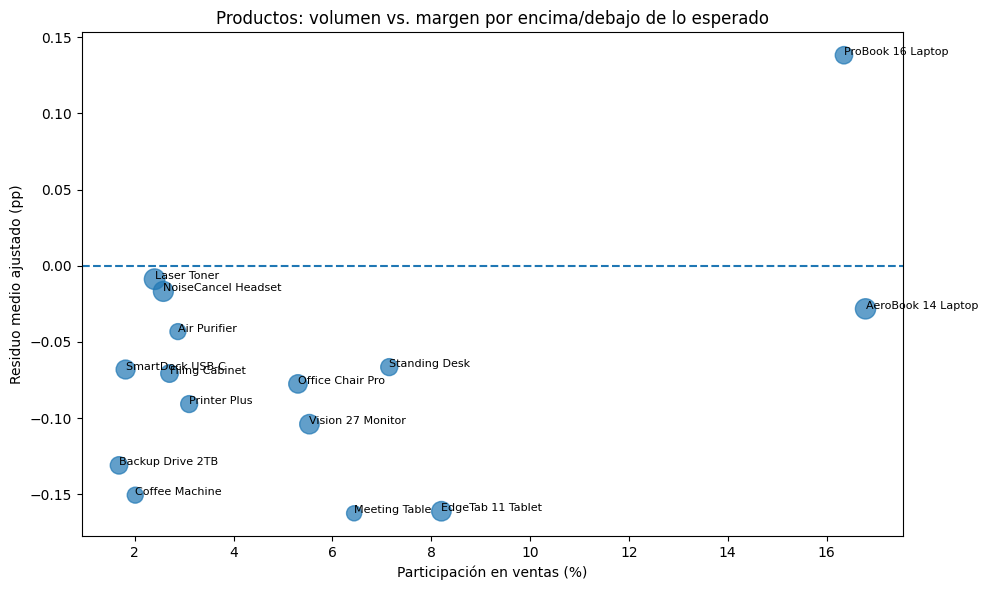

In [ ]:

# Visualización para los productos con mayor participación en ventas.

productos_op = (
    tabla_oportunidades[
        tabla_oportunidades[
            "Variable"
        ] == "Product_Name"
    ]
    .nlargest(
        15,
        "Participacion_ventas_pct"
    )
    .copy()
)

if len(
    productos_op
) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.scatter(
        productos_op[
            "Participacion_ventas_pct"
        ],
        productos_op[
            "Residuo_medio"
        ],
        s=(
            40
            + productos_op["N"]
            / productos_op["N"].max()
            * 180
        ),
        alpha=0.7
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    for _, fila in productos_op.iterrows():

        plt.annotate(
            str(
                fila["Nivel"]
            ),
            (
                fila[
                    "Participacion_ventas_pct"
                ],
                fila[
                    "Residuo_medio"
                ]
            ),
            fontsize=8
        )

    plt.xlabel(
        "Participación en ventas (%)"
    )

    plt.ylabel(
        "Residuo medio ajustado (pp)"
    )

    plt.title(
        "Productos: volumen vs. margen por encima/debajo de lo esperado"
    )

    plt.tight_layout()
    plt.show()



### Lectura para negocio

La matriz ayuda a distinguir:

**Alto volumen + residuo negativo**  
→ revisar condiciones, mix o política comercial.

**Alto volumen + residuo positivo**  
→ operación relevante que está rindiendo por encima de lo esperado.

**Bajo volumen + residuo positivo**  
→ oportunidad para investigar si existe potencial de crecimiento.

La palabra clave es **investigar**, no asumir causalidad.


# 21. ¿Necesitamos todas las variables?

La importancia por permutación puede sugerir que gran parte de la señal se concentra en pocas variables.

Para comprobarlo **sin usar el test para seleccionar variables**, hacemos un experimento adicional mediante validación cruzada solamente sobre `X_train`.

Comparamos:

1. todas las variables;
2. producto + descuento + precio + categoría;
3. producto + descuento;
4. todas menos `Product_Name`;
5. solo descuento.

Usamos el mismo algoritmo que fue seleccionado previamente. De esta manera cambia principalmente la información disponible, no la familia del modelo.

In [ ]:
feature_sets = {
    "Todas las variables":
        features,

    "Producto + descuento + precio + categoría": [
        "Product_Name",
        "Discount_Percentage",
        "Unit_Price",
        "Product_Category"
    ],

    "Producto + descuento": [
        "Product_Name",
        "Discount_Percentage"
    ],

    "Sin Product_Name": [
        c for c in features
        if c != "Product_Name"
    ],

    "Solo descuento": [
        "Discount_Percentage"
    ]
}

resultados_features = []

for nombre_set, cols in feature_sets.items():

    prep_subset = crear_preprocesador(
        mejor_imputacion,
        mejor_scaler,
        subset_features=cols
    )

    modelo_subset = Pipeline([
        ("prep", prep_subset),
        (
            "reg",
            clone(
                mejor_modelo.named_steps["reg"]
            )
        )
    ])

    scores = cross_validate(
        modelo_subset,
        X_train[cols],
        y_train,
        cv=cv_modelos,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultados_features.append({
        "Conjunto": nombre_set,
        "N_variables_originales": len(cols),
        "MAE_CV": -scores["test_mae"].mean(),
        "R2_CV": scores["test_r2"].mean()
    })


tabla_features = (
    pd.DataFrame(
        resultados_features
    )
    .sort_values("MAE_CV")
    .reset_index(drop=True)
)

display(
    tabla_features.round(4)
)

,Conjunto,N_variables_originales,MAE_CV,R2_CV
0,Todas las variables,17,1.9011,0.6825
1,Producto + descuento + precio + categoría,4,1.9388,0.6695
2,Sin Product_Name,16,1.9517,0.6812
3,Producto + descuento,2,2.6007,0.6428
4,Solo descuento,1,6.4561,0.2818


## Cómo interpretar esta comparación

Si un conjunto pequeño obtiene un MAE muy parecido al modelo completo, podemos concluir que gran parte de la **señal predictiva del margen** se concentra en esas variables.

Esto no significa que las demás variables sean inútiles para el negocio. Pueden seguir siendo importantes para volumen, segmentación, campañas u operaciones, aunque aporten poco para explicar la eficiencia de margen.

# 22. Análisis de errores por segmentos

Un MAE global puede ocultar zonas problemáticas.

Revisamos si el modelo se equivoca más por:

- trimestre;
- categoría;
- producto;
- canal.

Esto ayuda a detectar segmentos donde hacen falta mejores datos o donde el comportamiento es más difícil de modelar.

In [ ]:
evaluacion = X_test.copy()

evaluacion[
    "Profit_Margin_real"
] = y_test.values

evaluacion[
    "Profit_Margin_pred"
] = pred_test

evaluacion[
    "Error_Absoluto"
] = np.abs(
    evaluacion[
        "Profit_Margin_real"
    ]
    - evaluacion[
        "Profit_Margin_pred"
    ]
)


for variable in [
    "Order_Quarter",
    "Product_Category",
    "Product_Name",
    "Sales_Channel"
]:

    print(
        "\nERROR POR:",
        variable
    )

    tabla_error = (
        evaluacion
        .groupby(variable)[
            "Error_Absoluto"
        ]
        .agg(
            ["mean", "median", "count"]
        )
        .sort_values(
            "mean",
            ascending=False
        )
    )

    display(
        tabla_error.head(15).round(3)
    )


ERROR POR: Order_Quarter


,mean,median,count
Order_Quarter,,,
3,1.954,1.295,783
4,1.871,1.478,1180
1,1.740,1.239,746
2,1.665,1.357,891



ERROR POR: Product_Category


,mean,median,count
Product_Category,,,
Office Supplies,1.864,1.371,903
Electronics,1.848,1.366,1616
Appliances,1.742,1.270,398
Furniture,1.693,1.398,683



ERROR POR: Product_Name


,mean,median,count
Product_Name,,,
Notebook Pack,2.378,1.482,175
Office Keyboard,2.279,1.257,154
Desk Fan,2.227,1.601,138
Precision Mouse,2.177,1.223,187
Vision 27 Monitor,2.068,1.458,112
Copy Paper Box,1.975,1.473,184
Webcam HD,1.958,1.368,141
Backup Drive 2TB,1.905,1.388,112
Printer Plus,1.850,1.589,82



ERROR POR: Sales_Channel


,mean,median,count
Sales_Channel,,,
Online,1.863,1.384,1717
Retail Store,1.859,1.369,1180
B2B Portal,1.623,1.358,427
Phone Order,1.574,1.198,276


# 23. Aplicación de negocio: alerta de baja rentabilidad

Mantenemos la regresión como problema principal.

Después traducimos el margen predicho a una regla de negocio.

Ejemplo:

`margen predicho < 15 % → alerta`

### Ventaja

Si mañana el negocio cambia 15 % por 12 % o 18 %, no necesitamos redefinir ni reentrenar el problema como clasificación.

El umbral de 15 % se usa como ejemplo y debe ser validado con el área financiera.

In [ ]:
UMBRAL_MARGEN = 15.0

alerta_real = (
    y_test < UMBRAL_MARGEN
).astype(int)

alerta_pred = (
    pred_test < UMBRAL_MARGEN
).astype(int)

precision_alerta = precision_score(
    alerta_real,
    alerta_pred,
    zero_division=0
)

recall_alerta = recall_score(
    alerta_real,
    alerta_pred,
    zero_division=0
)

f1_alerta = f1_score(
    alerta_real,
    alerta_pred,
    zero_division=0
)

print(
    f"Umbral operativo: {UMBRAL_MARGEN}%"
)

print(
    f"Precision: {precision_alerta:.4f}"
)

print(
    f"Recall   : {recall_alerta:.4f}"
)

print(
    f"F1       : {f1_alerta:.4f}"
)

Umbral operativo: 15.0%
Precision: 0.8818
Recall   : 0.8802
F1       : 0.8810


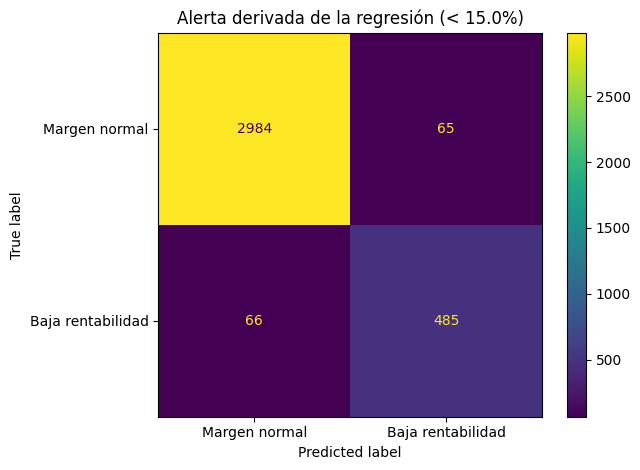

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    alerta_real,
    alerta_pred,
    display_labels=[
        "Margen normal",
        "Baja rentabilidad"
    ]
)

plt.title(
    f"Alerta derivada de la regresión (< {UMBRAL_MARGEN}%)"
)

plt.tight_layout()
plt.show()

# 24. Simulación predictiva: descuento por producto

Construimos una transacción representativa y modificamos el descuento para varios productos.

Para cada producto utilizamos su categoría y precio típico, mientras mantenemos valores representativos para las demás variables.

Después observamos cómo cambia el margen predicho.

> Esta es una **simulación predictiva**, no una estimación causal.

El gráfico permite comparar qué tan cerca queda cada producto del umbral de rentabilidad al variar el descuento, pero la interpretación depende del tipo de modelo seleccionado.

In [ ]:
fila_base = {}

for col in numeric_features:

    fila_base[col] = (
        X_train[col]
        .median()
    )

for col in ordinal_features + nominal_features:

    fila_base[col] = (
        X_train[col]
        .mode(dropna=True)
        .iloc[0]
    )


productos_demo = (
    X_train["Product_Name"]
    .value_counts()
    .head(6)
    .index
    .tolist()
)

descuentos_demo = np.arange(
    0,
    31,
    5
)

simulaciones = []

for producto in productos_demo:

    datos_producto = X_train[
        X_train["Product_Name"]
        == producto
    ]

    if len(datos_producto) == 0:
        continue

    precio_tipico = (
        datos_producto[
            "Unit_Price"
        ]
        .median()
    )

    categoria_tipica = (
        datos_producto[
            "Product_Category"
        ]
        .mode()
        .iloc[0]
    )

    for descuento in descuentos_demo:

        fila = fila_base.copy()

        fila.update({
            "Product_Name": producto,
            "Product_Category": categoria_tipica,
            "Unit_Price": precio_tipico,
            "Discount_Percentage": float(descuento)
        })

        fila_df = pd.DataFrame(
            [fila]
        )[features]

        margen_pred = (
            mejor_modelo
            .predict(
                fila_df
            )[0]
        )

        simulaciones.append({
            "Product_Name": producto,
            "Discount_Percentage": descuento,
            "Profit_Margin_pred": margen_pred
        })


df_simulacion = pd.DataFrame(
    simulaciones
)

display(
    df_simulacion.head(20).round(3)
)

,Product_Name,Discount_Percentage,Profit_Margin_pred
0,Copy Paper Box,0,18.526
1,Copy Paper Box,5,13.732
2,Copy Paper Box,10,8.174
3,Copy Paper Box,15,4.784
4,Copy Paper Box,20,-2.848
5,Copy Paper Box,25,-6.331
6,Copy Paper Box,30,-6.331
7,Precision Mouse,0,37.607
8,Precision Mouse,5,34.982
9,Precision Mouse,10,31.365


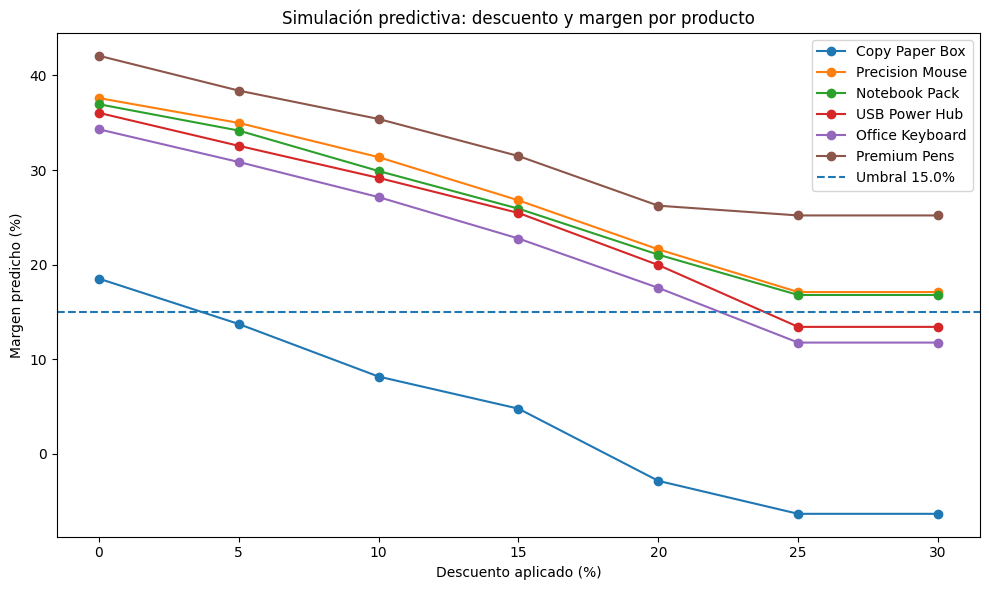

In [ ]:
plt.figure(
    figsize=(10, 6)
)

for producto in productos_demo:

    sub = df_simulacion[
        df_simulacion[
            "Product_Name"
        ] == producto
    ]

    plt.plot(
        sub[
            "Discount_Percentage"
        ],
        sub[
            "Profit_Margin_pred"
        ],
        marker="o",
        label=producto
    )

plt.axhline(
    UMBRAL_MARGEN,
    linestyle="--",
    label=f"Umbral {UMBRAL_MARGEN}%"
)

plt.xlabel(
    "Descuento aplicado (%)"
)

plt.ylabel(
    "Margen predicho (%)"
)

plt.title(
    "Simulación predictiva: descuento y margen por producto"
)

plt.legend()

plt.tight_layout()
plt.show()

## 24.1 Limitación clave: producto × descuento

Si el modelo seleccionado es **Regresión Lineal o Ridge**, no hemos incluido explícitamente una interacción:

`Product_Name × Discount_Percentage`

Eso significa que cada producto puede tener un margen base diferente, pero el efecto lineal del descuento es esencialmente común entre productos.

Por lo tanto, **no debemos afirmar que el modelo demostró elasticidades o sensibilidades distintas al descuento para cada producto**.

La conclusión correcta es:

> Debido a sus distintos márgenes base, diferentes productos pueden alcanzar el umbral de rentabilidad con niveles distintos de descuento según la predicción del modelo.

Para estudiar sensibilidad específica por producto haría falta incluir interacciones explícitas o utilizar un diseño analítico orientado a ese objetivo.

In [ ]:
if mejor_nombre in [
    "Regresión lineal",
    "Ridge",
    "Ridge tuneado"
]:

    print(
        "Modelo lineal seleccionado."
    )

    print(
        "La simulación no incluye una interacción "
        "explícita Producto × Descuento."
    )

else:

    print(
        "Modelo no lineal seleccionado."
    )

    print(
        "Puede capturar algunas interacciones de forma implícita, "
        "pero la simulación sigue siendo predictiva y no causal."
    )

Modelo no lineal seleccionado.
Puede capturar algunas interacciones de forma implícita, pero la simulación sigue siendo predictiva y no causal.


## 24.2 Mayor descuento probado que conserva el margen de referencia

Dentro de los niveles simulados buscamos el mayor descuento que mantiene:

`Profit_Margin_pred >= 15 %`

Este resultado es **orientativo**. No demuestra una elasticidad propia del producto ni debe convertirse automáticamente en política comercial.

In [ ]:
topes = []

for producto in productos_demo:

    sub = (
        df_simulacion[
            df_simulacion[
                "Product_Name"
            ] == producto
        ]
        .sort_values(
            "Discount_Percentage"
        )
    )

    seguros = sub[
        sub[
            "Profit_Margin_pred"
        ] >= UMBRAL_MARGEN
    ]

    if len(seguros) > 0:

        tope = seguros[
            "Discount_Percentage"
        ].max()

    else:

        tope = np.nan

    topes.append({
        "Product_Name": producto,
        "Mayor_descuento_probado_con_margen_seguro": tope
    })


tabla_topes = pd.DataFrame(
    topes
)

display(tabla_topes)

,Product_Name,Mayor_descuento_probado_con_margen_seguro
0,Copy Paper Box,0
1,Precision Mouse,30
2,Notebook Pack,30
3,USB Power Hub,20
4,Office Keyboard,20
5,Premium Pens,30


# 25. Conclusión metodológica

Este notebook conserva la pregunta original de rentabilidad como **regresión** y reúne las fortalezas metodológicas y de negocio de las versiones comparadas.

La lógica final es:

### EDA + incertidumbre
Además de márgenes agregados, usamos bootstrap para dar contexto a diferencias descriptivas clave.

### Cuatro etapas de preprocesamiento
Justificamos imputación, codificación, escalado y tratamiento de texto.

### Prevención de leakage
Excluimos variables que reconstruyen el target o no existirían al momento de la predicción.

### Group leakage
Verificamos si el desempeño depende de compartir pedidos o clientes entre folds.

### Baseline + comparación de modelos
Comparamos modelos simples y complejos bajo el mismo protocolo.

### Cross-validation
Las decisiones se toman dentro de train.

### Optuna
Tuneamos modelos sin utilizar test y analizamos la relevancia de hiperparámetros.

### Parsimonia
Una mejora mínima no justifica automáticamente mayor complejidad.

### Test final
El conjunto reservado se utiliza para medir generalización.

### Calidad del target
Medimos el efecto de inconsistencias financieras sin borrar casos después de observar los resultados.

### Drift y validación temporal
PSI, validación adversarial y prueba 2022–2024 → 2025 permiten estudiar estabilidad.

### Interpretabilidad
Combinamos permutation importance y SHAP.

### Bloque diferencial
Estimamos un margen económico esperado mediante predicciones OOF y calculamos un `Residuo_Ajustado`.

Esto permite comparar:

- margen crudo;
- diferencia que permanece después de controlar estadísticamente producto y condiciones de venta.

### Capacidad predictiva por dimensiones
Para Venta, Producto, Cliente, Canal y Periodo medimos:

- desempeño usando solo esa dimensión;
- pérdida de desempeño al retirarla del modelo completo.

### Matriz volumen vs. eficiencia ajustada
Integramos participación en ventas con margen por encima/debajo de lo esperado para priorizar oportunidades de investigación comercial.

### Aplicación
Convertimos el margen predicho en una alerta y exploramos escenarios de descuento.

---